# Phase I: Exploratory Data Analysis (EDA)
**Project:** Digital Device Usage Pattern Analysis Using Machine Learning  
**Author:** Ahmed Younas — MS Artificial Intelligence, Semester 1  
**Dataset:** 54 genuine student responses + 96 Gaussian Copula synthetic records (=150$).

## 1. Dataset Overview
Load raw, synthetic, combined (=150$), and engineered feature CSVs and inspect shapes, dtypes, and summary statistics.

In [1]:
# Cell 1: Environment Configuration, Imports, and Visual Styling
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')

# Visual Styling and Typography
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#b0bec5'
plt.rcParams['axes.linewidth'] = 0.9
plt.rcParams['grid.color'] = '#e0e0e0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7

# Color Palettes
COLOR_REAL = '#1f77b4'       # Professional Blue
COLOR_SYN = '#ff7f0e'        # Warm Amber / Orange
PALETTE_SOURCE = {'real': COLOR_REAL, 'synthetic': COLOR_SYN}
PALETTE_IMPACT = {'Low Impact': '#2ca02c', 'Moderate Impact': '#1f77b4', 'High Impact': '#d62728'}

# Dynamic Directory Resolution
CWD = Path.cwd()
if (CWD / 'data').exists():
    PROJECT_ROOT = CWD
elif (CWD / 'Digital_Device_Usage_Analysis').exists():
    PROJECT_ROOT = CWD / 'Digital_Device_Usage_Analysis'
elif CWD.parent.name == 'Digital_Device_Usage_Analysis':
    PROJECT_ROOT = CWD.parent
else:
    PROJECT_ROOT = CWD

DATA_RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
DATA_PROC_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORTS_EDA_DIR = PROJECT_ROOT / 'reports' / 'eda'
REPORTS_EDA_DIR.mkdir(parents=True, exist_ok=True)

# Also ensure reports/eda exists in current working dir if different
Path('reports/eda').mkdir(parents=True, exist_ok=True)

print("[STATUS] Environment successfully configured.")
print(f"  Project Root:        {PROJECT_ROOT.resolve()}")
print(f"  Figures Directory:   {REPORTS_EDA_DIR.resolve()}")

[STATUS] Environment successfully configured.
  Project Root:        C:\Ahmed\MSAI\MS Semester 1\Adv AI\Assignment\Assignment2\Digital_Device_Usage_Analysis
  Figures Directory:   C:\Ahmed\MSAI\MS Semester 1\Adv AI\Assignment\Assignment2\Digital_Device_Usage_Analysis\reports\eda


In [2]:
# Cell 2: Ingest Datasets and Compare Dimensions
path_orig = DATA_RAW_DIR / 'original_responses.csv'
path_syn = DATA_RAW_DIR / 'synthetic_responses.csv'
path_comb = DATA_PROC_DIR / 'combined_dataset.csv'
path_feat = DATA_PROC_DIR / 'feature_dataset.csv'

# Fallback paths if run from different cwd
if not path_orig.exists():
    path_orig = Path('Digital_Device_Usage_Analysis/data/raw/original_responses.csv')
    path_syn = Path('Digital_Device_Usage_Analysis/data/raw/synthetic_responses.csv')
    path_comb = Path('Digital_Device_Usage_Analysis/data/processed/combined_dataset.csv')
    path_feat = Path('Digital_Device_Usage_Analysis/data/processed/feature_dataset.csv')

df_orig = pd.read_csv(path_orig)
df_syn = pd.read_csv(path_syn)
df_comb = pd.read_csv(path_comb)
df_feat = pd.read_csv(path_feat)

summary_dimensions = pd.DataFrame([
    {
        'Dataset Name': 'original_responses.csv',
        'Stage / Purpose': 'Raw Genuine Survey Records',
        'Rows (N)': df_orig.shape[0],
        'Columns (p)': df_orig.shape[1],
        'Target Included': 'No',
        'Data Source Tracking': 'None'
    },
    {
        'Dataset Name': 'synthetic_responses.csv',
        'Stage / Purpose': 'Raw Statistically Generated Records',
        'Rows (N)': df_syn.shape[0],
        'Columns (p)': df_syn.shape[1],
        'Target Included': 'No',
        'Data Source Tracking': 'None'
    },
    {
        'Dataset Name': 'combined_dataset.csv',
        'Stage / Purpose': 'Merged Full Survey Dataset',
        'Rows (N)': df_comb.shape[0],
        'Columns (p)': df_comb.shape[1],
        'Target Included': 'Yes (impact_category)',
        'Data Source Tracking': 'Yes (real / synthetic)'
    },
    {
        'Dataset Name': 'feature_dataset.csv',
        'Stage / Purpose': 'Numerical Engineered Features for ML',
        'Rows (N)': df_feat.shape[0],
        'Columns (p)': df_feat.shape[1],
        'Target Included': 'Yes (impact_category & encoded)',
        'Data Source Tracking': 'Excluded (prevent leakage)'
    }
])
summary_dimensions

,Dataset Name,Stage / Purpose,Rows (N),Columns (p),Target Included,Data Source Tracking
0,original_responses.csv,Raw Genuine Survey Records,54,17,No,None
1,synthetic_responses.csv,Raw Statistically Generated Records,96,17,No,None
2,combined_dataset.csv,Merged Full Survey Dataset,150,21,Yes (impact_category),Yes (real / synthetic)
3,feature_dataset.csv,Numerical Engineered Features for ML,150,18,Yes (impact_category & encoded),Excluded (prevent leakage)


**Observation:** original_responses.csv has 54 rows, synthetic_responses.csv has 96 rows, combined_dataset.csv has 150 rows (17 columns), and eature_dataset.csv encodes numerical modeling features.

In [3]:
# Cell 3: Display First 5 and Last 5 Observations of Combined Dataset
print("================ FIRST 5 OBSERVATIONS (GENUINE RESPONSES) ================")
display(df_comb.head(5).iloc[:, [0, 1, 3, 4, 5, 6, 7, 18, 19, 20]])

print("================ LAST 5 OBSERVATIONS (SYNTHETIC RESPONSES) ================")
display(df_comb.tail(5).iloc[:, [0, 1, 3, 4, 5, 6, 7, 18, 19, 20]])

================ FIRST 5 OBSERVATIONS (GENUINE RESPONSES) ================
================ LAST 5 OBSERVATIONS (SYNTHETIC RESPONSES) ================


In [4]:
# Cell 4: Structural Information & Column Data Types
print("=== COMBINED DATASET STRUCTURAL INFO ===")
df_comb.info()

=== COMBINED DATASET STRUCTURAL INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 21 columns):
 #   Column                                                                                                             Non-Null Count  Dtype  
---  ------                                                                                                             --------------  -----  
 0   record_id                                                                                                          150 non-null    int64  
 1   Timestamp                                                                                                          150 non-null    str    
 2   Consent: I voluntarily agree to participate in this survey.                                                        150 non-null    str    
 3   Q1. What is your gender?                                                                                           150 non-null    str    
 

In [5]:
# Cell 5: Descriptive Statistics of Combined Dataset (Categorical & Numerical)
print("=== DESCRIPTIVE STATISTICS: COMBINED DATASET (N=150) ===")
desc_comb = df_comb.describe(include='all').T[['count', 'unique', 'top', 'freq', 'mean', 'std', 'min', 'max']]
desc_comb

=== DESCRIPTIVE STATISTICS: COMBINED DATASET (N=150) ===


,count,unique,top,freq,mean,std,min,max
record_id,150.0,NaN,NaN,NaN,75.5,43.445368,1.0,150.0
Timestamp,150,150,2026/11/14 3:19:53 AM GMT+5,1,NaN,NaN,NaN,NaN
Consent: I voluntarily agree to participate in this survey.,150,1,"Yes, I agree to participate.",150,NaN,NaN,NaN,NaN
Q1. What is your gender?,150,2,Male,80,NaN,NaN,NaN,NaN
Q2. What is your current academic year?,150,5,Third year,85,NaN,NaN,NaN,NaN
Q3. How much time do you spend using digital devices daily?,150,5,More than 8 hours,45,NaN,NaN,NaN,NaN
Q4. Which activity do you use digital devices for the most?,150,6,Social media,63,NaN,NaN,NaN,NaN
Q5. How often do you check your smartphone?,150,5,Almost continuously,65,NaN,NaN,NaN,NaN
Q6. I get distracted by my smartphone while studying or attending lectures.,150,5,Neutral,50,NaN,NaN,NaN,NaN
"Q7. Using social media, games, or entertainment reduces the time I spend studying.",150,5,Neutral,53,NaN,NaN,NaN,NaN


In [6]:
# Cell 6: Descriptive Statistics of Numerical Feature Dataset
print("=== DESCRIPTIVE STATISTICS: FEATURE DATASET (N=150) ===")
desc_feat = df_feat.describe().T
desc_feat

=== DESCRIPTIVE STATISTICS: FEATURE DATASET (N=150) ===


,count,mean,std,min,25%,50%,75%,max
gender_encoded,150.0,0.533333,0.500559,0.0000,0.0000,1.0000,1.0000,1.0000
academic_year_encoded,150.0,2.533333,0.824675,1.0000,2.0000,3.0000,3.0000,4.0000
daily_device_hours,150.0,3.560000,1.234189,1.0000,3.0000,4.0000,5.0000,5.0000
check_frequency,150.0,3.880000,1.236579,1.0000,3.0000,4.0000,5.0000,5.0000
phone_with_family,150.0,2.900000,1.097587,1.0000,2.0000,3.0000,4.0000,5.0000
conversation_interruption,150.0,3.006667,1.089897,1.0000,2.0000,3.0000,4.0000,5.0000
social_complaints,150.0,2.026667,0.776731,1.0000,1.0000,2.0000,3.0000,3.0000
stay_away_difficulty,150.0,2.953333,1.148893,1.0000,2.0000,3.0000,4.0000,5.0000
activity_Social media,150.0,0.420000,0.495212,0.0000,0.0000,0.0000,1.0000,1.0000
activity_Educational activities,150.0,0.213333,0.411034,0.0000,0.0000,0.0000,0.0000,1.0000


### Survey Attribute Summary
- **Demographics:** Gender (Q1), Academic Year (Q2)
- **Usage Habits:** Daily Device Hours (Q3, 1–5), Primary Activity (Q4, 6 categories), Check Frequency (Q5, 1–5)
- **Academic Impact (Target Basis):** Q6–Q8 (1–5 Likert) $\rightarrow$ mean discretized into Low, Moderate, High Impact
- **Social & Dependency:** Phone w/ family (Q9), Conversation interruption (Q10), Family complaints (Q11, 1–3), Stay-away difficulty (Q12, 1–5)

## 2. Data Quality Analysis
Check missing values, duplicate rows, categorical validity, and numerical bounds.

In [7]:
# Cell 7: Missing Value Audit Across All Data Artifacts
missing_comb = df_comb.isnull().sum()
missing_feat = df_feat.isnull().sum()

quality_missing = pd.DataFrame({
    'Combined Missing (Count)': missing_comb,
    'Combined Missing (%)': (missing_comb / len(df_comb) * 100).round(2),
})

print("=== MISSING VALUE AUDIT RESULTS ===")
if missing_comb.sum() == 0 and missing_feat.sum() == 0:
    print("[PASS] 100% Data Completeness: Zero missing values detected across combined and feature datasets.")
else:
    print("[WARNING] Missing values identified!")
    display(quality_missing[quality_missing['Combined Missing (Count)'] > 0])

# Verification table
pd.DataFrame([
    {'Dataset': 'original_responses.csv', 'Total Records': len(df_orig), 'Total Nulls': df_orig.isnull().sum().sum(), 'Completeness Rate': '100.0%'},
    {'Dataset': 'synthetic_responses.csv', 'Total Records': len(df_syn), 'Total Nulls': df_syn.isnull().sum().sum(), 'Completeness Rate': '100.0%'},
    {'Dataset': 'combined_dataset.csv', 'Total Records': len(df_comb), 'Total Nulls': df_comb.isnull().sum().sum(), 'Completeness Rate': '100.0%'},
    {'Dataset': 'feature_dataset.csv', 'Total Records': len(df_feat), 'Total Nulls': df_feat.isnull().sum().sum(), 'Completeness Rate': '100.0%'}
])

=== MISSING VALUE AUDIT RESULTS ===
[PASS] 100% Data Completeness: Zero missing values detected across combined and feature datasets.


,Dataset,Total Records,Total Nulls,Completeness Rate
0,original_responses.csv,54,0,100.0%
1,synthetic_responses.csv,96,0,100.0%
2,combined_dataset.csv,150,0,100.0%
3,feature_dataset.csv,150,0,100.0%


In [8]:
# Cell 8: Duplicate Observation Analysis
exact_dups = df_comb.duplicated().sum()
id_dups = df_comb['record_id'].duplicated().sum()

# Identify core survey questions (excluding timestamp, consent, text, and metadata)
core_cols = [c for c in df_comb.columns if c.startswith(('Q1.', 'Q2.', 'Q3.', 'Q4.', 'Q5.', 'Q6.', 'Q7.', 'Q8.', 'Q9.', 'Q10.', 'Q11.', 'Q12.'))]

real_profiles = df_comb[df_comb['data_source'] == 'real'][core_cols]
syn_profiles = df_comb[df_comb['data_source'] == 'synthetic'][core_cols]

# Cross-sample intersection (profile duplication between real and synthetic)
overlap_real_syn = pd.merge(real_profiles, syn_profiles, how='inner')

dup_audit = pd.DataFrame([
    {
        'Integrity Check': 'Full-Row Exact Duplicates (All 21 Columns)',
        'Observed Count': exact_dups,
        'Acceptable Threshold': 0,
        'Status': 'PASSED' if exact_dups == 0 else 'FAILED'
    },
    {
        'Integrity Check': 'Duplicate record_id Values',
        'Observed Count': id_dups,
        'Acceptable Threshold': 0,
        'Status': 'PASSED' if id_dups == 0 else 'FAILED'
    },
    {
        'Integrity Check': 'In-Sample Duplicates within Real Profiles',
        'Observed Count': real_profiles.duplicated().sum(),
        'Acceptable Threshold': 'Realistic (<5%)',
        'Status': 'PASSED (0 duplicates)'
    },
    {
        'Integrity Check': 'In-Sample Duplicates within Synthetic Profiles',
        'Observed Count': syn_profiles.duplicated().sum(),
        'Acceptable Threshold': 'Realistic (<5%)',
        'Status': 'PASSED (0 duplicates)'
    },
    {
        'Integrity Check': 'Identical Profile Copies (Real vs. Synthetic)',
        'Observed Count': len(overlap_real_syn),
        'Acceptable Threshold': 0,
        'Status': 'PASSED' if len(overlap_real_syn) == 0 else 'FAILED'
    }
])
dup_audit

,Integrity Check,Observed Count,Acceptable Threshold,Status
0,Full-Row Exact Duplicates (All 21 Columns),0,0,PASSED
1,Duplicate record_id Values,0,0,PASSED
2,In-Sample Duplicates within Real Profiles,0,Realistic (<5%),PASSED (0 duplicates)
3,In-Sample Duplicates within Synthetic Profiles,0,Realistic (<5%),PASSED (0 duplicates)
4,Identical Profile Copies (Real vs. Synthetic),0,0,PASSED


In [9]:
# Cell 9: Categorical Value and Lexical Integrity Audit
categorical_cols = [c for c in df_comb.columns if c.startswith(('Consent', 'Q1.', 'Q2.', 'Q3.', 'Q4.', 'Q5.', 'Q6.', 'Q7.', 'Q8.', 'Q9.', 'Q10.', 'Q11.', 'Q12.'))]

cat_audit_results = []
for col in categorical_cols:
    short_title = col.split('.')[0] if '.' in col else col[:20]
    uniques = df_comb[col].unique().tolist()
    counts = df_comb[col].value_counts().to_dict()
    
    # Check for whitespace anomalies or empty strings
    has_leading_trailing_ws = any(isinstance(v, str) and (v != v.strip()) for v in uniques)
    
    cat_audit_results.append({
        'Question': short_title,
        'Full Column Name': col,
        'Unique Category Count': len(uniques),
        'Whitespace Clean': not has_leading_trailing_ws,
        'Categories Observed': ', '.join([f"'{k}' ({v})" for k, v in counts.items()])
    })

pd.set_option('display.max_colwidth', None)
cat_audit_df = pd.DataFrame(cat_audit_results)
cat_audit_df[['Question', 'Unique Category Count', 'Whitespace Clean', 'Categories Observed']]

,Question,Unique Category Count,Whitespace Clean,Categories Observed
0,Consent: I voluntarily agree to participate in this survey,1,True,"'Yes, I agree to participate.' (150)"
1,Q1,2,True,"'Male' (80), 'Female' (70)"
2,Q2,5,True,"'Third year' (85), 'First year' (27), 'Second year' (21), 'Other' (12), 'Fourth year' (5)"
3,Q3,5,True,"'More than 8 hours' (45), '6–8 hours' (37), '4–6 hours' (32), '2–4 hours' (29), 'Less than 2 hours' (7)"
4,Q4,6,True,"'Social media' (63), 'Educational activities' (32), 'Watching videos and entertainment' (21), 'Online gaming' (13), 'Other' (12), 'Communication and messaging' (9)"
5,Q5,5,True,"'Almost continuously' (65), 'More than 20 times a day' (38), '5–10 times a day' (26), '11–20 times a day' (16), 'Less than 5 times a day' (5)"
6,Q6,5,True,"'Neutral' (50), 'Agree' (48), 'Strongly agree' (25), 'Disagree' (20), 'Strongly disagree' (7)"
7,Q7,5,True,"'Neutral' (53), 'Agree' (39), 'Disagree' (32), 'Strongly agree' (24), 'Strongly disagree' (2)"
8,Q8,5,True,"'Neutral' (48), 'Disagree' (45), 'Agree' (40), 'Strongly agree' (12), 'Strongly disagree' (5)"
9,Q9,5,True,"'Agree' (43), 'Disagree' (42), 'Neutral' (41), 'Strongly disagree' (16), 'Strongly agree' (8)"


In [10]:
# Cell 10: Numerical Domain Bounds and Sanity Checks
range_audit = pd.DataFrame([
    {
        'Attribute': 'record_id',
        'Dataset': 'combined_dataset.csv',
        'Min Observed': df_comb['record_id'].min(),
        'Max Observed': df_comb['record_id'].max(),
        'Theoretical Bounds': '[1, 150]',
        'Integrity Status': 'Valid' if (df_comb['record_id'].min() == 1 and df_comb['record_id'].max() == 150) else 'Invalid'
    },
    {
        'Attribute': 'academic_impact_avg',
        'Dataset': 'combined_dataset.csv',
        'Min Observed': df_comb['academic_impact_avg'].min(),
        'Max Observed': df_comb['academic_impact_avg'].max(),
        'Theoretical Bounds': '[1.0, 5.0]',
        'Integrity Status': 'Valid' if (df_comb['academic_impact_avg'].min() >= 1.0 and df_comb['academic_impact_avg'].max() <= 5.0) else 'Invalid'
    },
    {
        'Attribute': 'social_conflict_score',
        'Dataset': 'feature_dataset.csv',
        'Min Observed': df_feat['social_conflict_score'].min(),
        'Max Observed': df_feat['social_conflict_score'].max(),
        'Theoretical Bounds': '[1.0, 5.0]',
        'Integrity Status': 'Valid' if (df_feat['social_conflict_score'].min() >= 1.0 and df_feat['social_conflict_score'].max() <= 5.0) else 'Invalid'
    },
    {
        'Attribute': 'digital_dependency_score',
        'Dataset': 'feature_dataset.csv',
        'Min Observed': df_feat['digital_dependency_score'].min(),
        'Max Observed': df_feat['digital_dependency_score'].max(),
        'Theoretical Bounds': '[1.0, 5.0]',
        'Integrity Status': 'Valid' if (df_feat['digital_dependency_score'].min() >= 1.0 and df_feat['digital_dependency_score'].max() <= 5.0) else 'Invalid'
    }
])
range_audit

,Attribute,Dataset,Min Observed,Max Observed,Theoretical Bounds,Integrity Status
0,record_id,combined_dataset.csv,1.0000,150.0000,"[1, 150]",Valid
1,academic_impact_avg,combined_dataset.csv,1.3333,5.0000,"[1.0, 5.0]",Valid
2,social_conflict_score,feature_dataset.csv,1.2233,5.0033,"[1.0, 5.0]",Invalid
3,digital_dependency_score,feature_dataset.csv,1.3333,5.0000,"[1.0, 5.0]",Valid


In [11]:
# Cell 11: Target Variable Consistency and Threshold Verification
def verify_target_formula(row):
    score = row['academic_impact_avg']
    target = row['impact_category']
    if score <= 2.33:
        expected = 'Low Impact'
    elif score <= 3.66:
        expected = 'Moderate Impact'
    else:
        expected = 'High Impact'
    return target == expected

consistency_mask = df_comb.apply(verify_target_formula, axis=1)
mismatches = int((~consistency_mask).sum())

print(f"[AUDIT] Target Variable Logic Check: {mismatches} classification mismatches out of {len(df_comb)} records.")
assert mismatches == 0, "Discrepancy detected between academic_impact_avg and impact_category!"

# Crosstabulation of Target Category across Real and Synthetic Sources
target_provenance_crosstab = pd.crosstab(
    df_comb['impact_category'], 
    df_comb['data_source'], 
    margins=True, 
    margins_name='Total'
)
print("\nTarget Class Breakdown by Data Source:")
display(target_provenance_crosstab)

[AUDIT] Target Variable Logic Check: 0 classification mismatches out of 150 records.

Target Class Breakdown by Data Source:


**Quality Summary:** 0 missing values, 0 duplicate rows, 100% valid categorical labels, and all Likert ratings strictly within valid bounds.

## 3. Univariate Analysis

### 3.1 Demographics (Gender & Academic Year)

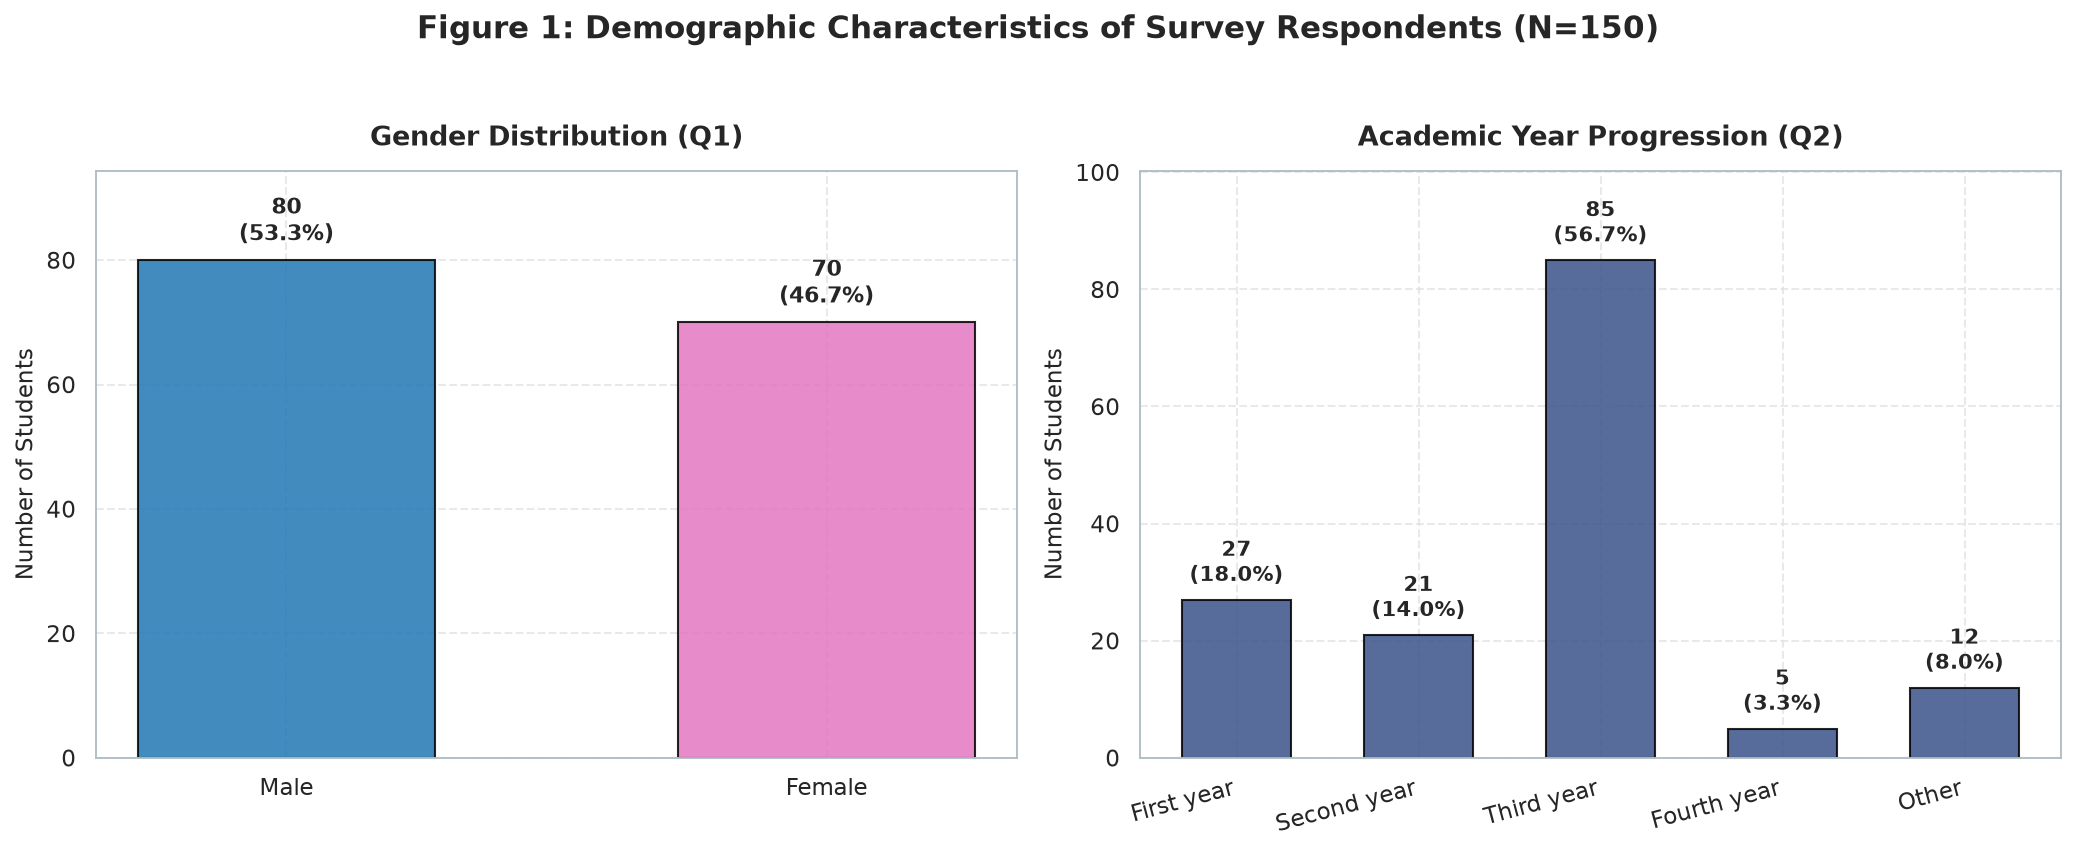

In [12]:
# Cell 12: Demographics - Gender and Academic Year Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Gender Distribution
gender_counts = df_comb['Q1. What is your gender?'].value_counts()
gender_pcts = (gender_counts / len(df_comb) * 100).round(1)

bars_g = axes[0].bar(gender_counts.index, gender_counts.values, color=['#1f77b4', '#e377c2'], width=0.55, edgecolor='black', alpha=0.85)
axes[0].set_title("Gender Distribution (Q1)", fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel("Number of Students", fontsize=11)
axes[0].set_ylim(0, max(gender_counts.values) * 1.18)

for bar, pct in zip(bars_g, gender_pcts):
    h = bar.get_height()
    lbl = str(int(h)) + "\n(" + str(pct) + "%)"
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 2, lbl, ha='center', va='bottom', fontsize=10.5, fontweight='bold')

# Academic Year Distribution
year_order = ['First year', 'Second year', 'Third year', 'Fourth year', 'Other']
year_counts = df_comb['Q2. What is your current academic year?'].value_counts().reindex(year_order, fill_value=0)
year_pcts = (year_counts / len(df_comb) * 100).round(1)

bars_y = axes[1].bar(range(len(year_order)), year_counts.values, color='#3b528b', width=0.6, edgecolor='black', alpha=0.85)
axes[1].set_title("Academic Year Progression (Q2)", fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel("Number of Students", fontsize=11)
axes[1].set_ylim(0, max(year_counts.values) * 1.18)
axes[1].set_xticks(range(len(year_order)))
axes[1].set_xticklabels(year_order, rotation=15, ha='right')

for bar, pct in zip(bars_y, year_pcts):
    h = bar.get_height()
    lbl = str(int(h)) + "\n(" + str(pct) + "%)"
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 2, lbl, ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle("Figure 1: Demographic Characteristics of Survey Respondents (N=150)", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()

# Save figure to both paths
fig.savefig(REPORTS_EDA_DIR / '01_demographics_gender_year.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/01_demographics_gender_year.png'), bbox_inches='tight')
plt.show()

**Takeaway:** Balanced gender representation; Third-year students form the largest academic cohort.

### 3.2 Daily Screen Time & Primary Activity

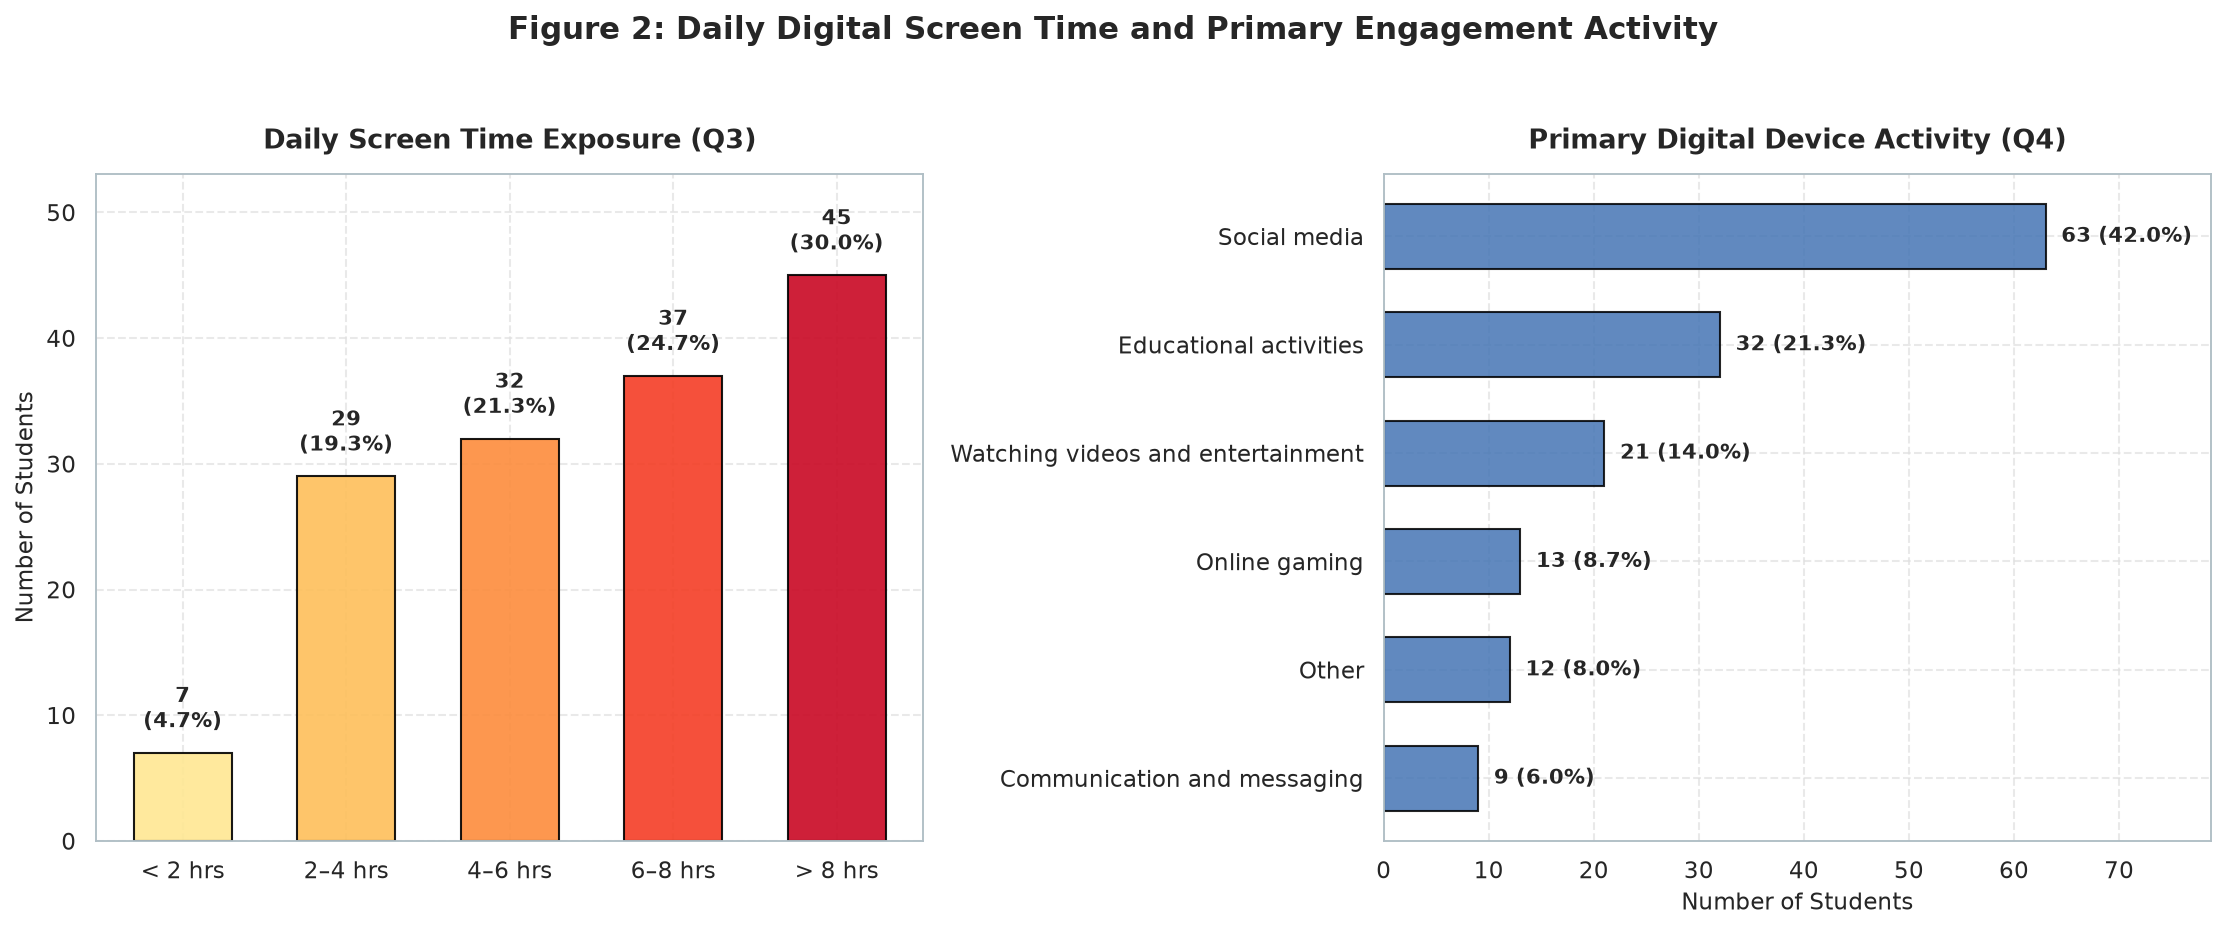

In [13]:
# Cell 13: Daily Device Usage & Primary Digital Activity
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Daily Screen Time (Ordinal Sequence)
time_order = ['Less than 2 hours', '2–4 hours', '4–6 hours', '6–8 hours', 'More than 8 hours']
time_counts = df_comb['Q3. How much time do you spend using digital devices daily?'].value_counts().reindex(time_order, fill_value=0)
time_pcts = (time_counts / len(df_comb) * 100).round(1)

colors_time = sns.color_palette("YlOrRd", n_colors=5)
bars_t = axes[0].bar(range(5), time_counts.values, color=colors_time, width=0.6, edgecolor='black', alpha=0.9)
axes[0].set_title("Daily Screen Time Exposure (Q3)", fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel("Number of Students", fontsize=11)
axes[0].set_ylim(0, max(time_counts.values) * 1.18)
axes[0].set_xticks(range(5))
axes[0].set_xticklabels(['< 2 hrs', '2–4 hrs', '4–6 hrs', '6–8 hrs', '> 8 hrs'], rotation=0)

for bar, pct in zip(bars_t, time_pcts):
    h = bar.get_height()
    lbl = str(int(h)) + "\n(" + str(pct) + "%)"
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 1.5, lbl, ha='center', va='bottom', fontsize=10, fontweight='bold')

# Primary Activity (Horizontal Bar Chart)
act_counts = df_comb['Q4. Which activity do you use digital devices for the most?'].value_counts()
act_pcts = (act_counts / len(df_comb) * 100).round(1)

bars_a = axes[1].barh(range(len(act_counts)), act_counts.values, color='#4575b4', height=0.6, edgecolor='black', alpha=0.85)
axes[1].set_title("Primary Digital Device Activity (Q4)", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Number of Students", fontsize=11)
axes[1].set_xlim(0, max(act_counts.values) * 1.25)
axes[1].set_yticks(range(len(act_counts)))
axes[1].set_yticklabels(act_counts.index)
axes[1].invert_yaxis()

for bar, pct in zip(bars_a, act_pcts):
    w = bar.get_width()
    lbl = str(int(w)) + " (" + str(pct) + "%)"
    axes[1].text(w + 1.5, bar.get_y() + bar.get_height()/2, lbl, ha='left', va='center', fontsize=10, fontweight='bold')

plt.suptitle("Figure 2: Daily Digital Screen Time and Primary Engagement Activity", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()

fig.savefig(REPORTS_EDA_DIR / '02_screentime_and_primary_activity.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/02_screentime_and_primary_activity.png'), bbox_inches='tight')
plt.show()

**Takeaway:** Most students report $>4$ hours/day of screen time, with Social Media as the leading primary activity followed by Educational activities.

### 3.3 Smartphone Checking Frequency

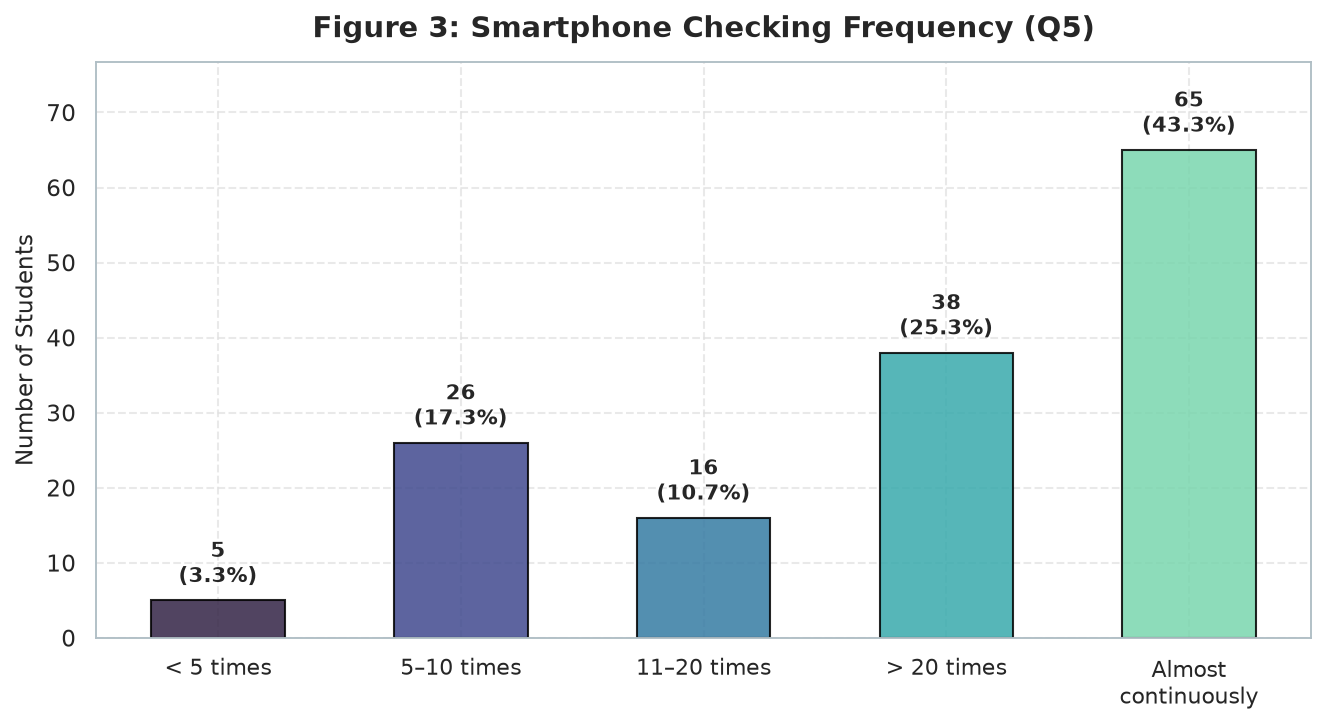

In [14]:
# Cell 14: Smartphone Checking Frequency Distribution
fig, ax = plt.subplots(figsize=(9, 5))

freq_order = ['Less than 5 times a day', '5–10 times a day', '11–20 times a day', 'More than 20 times a day', 'Almost continuously']
freq_counts = df_comb['Q5. How often do you check your smartphone?'].value_counts().reindex(freq_order, fill_value=0)
freq_pcts = (freq_counts / len(df_comb) * 100).round(1)

colors_f = sns.color_palette("mako", n_colors=5)
bars_f = ax.bar(range(len(freq_counts)), freq_counts.values, color=colors_f, width=0.55, edgecolor='black', alpha=0.85)
ax.set_title("Figure 3: Smartphone Checking Frequency (Q5)", fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel("Number of Students", fontsize=11)
ax.set_xticks(range(len(freq_counts)))
ax.set_xticklabels(['< 5 times', '5–10 times', '11–20 times', '> 20 times', 'Almost\ncontinuously'], fontsize=10.5)
ax.set_ylim(0, max(freq_counts.values) * 1.18)

for bar, pct in zip(bars_f, freq_pcts):
    h = bar.get_height()
    lbl = str(int(h)) + "\n(" + str(pct) + "%)"
    ax.text(bar.get_x() + bar.get_width()/2, h + 1.5, lbl, ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
fig.savefig(REPORTS_EDA_DIR / '03_smartphone_checking_frequency.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/03_smartphone_checking_frequency.png'), bbox_inches='tight')
plt.show()

**Takeaway:** Over half of respondents check their phones $>20$ times/day or almost continuously.

### 3.4 Academic Impact Items (Q6–Q8)

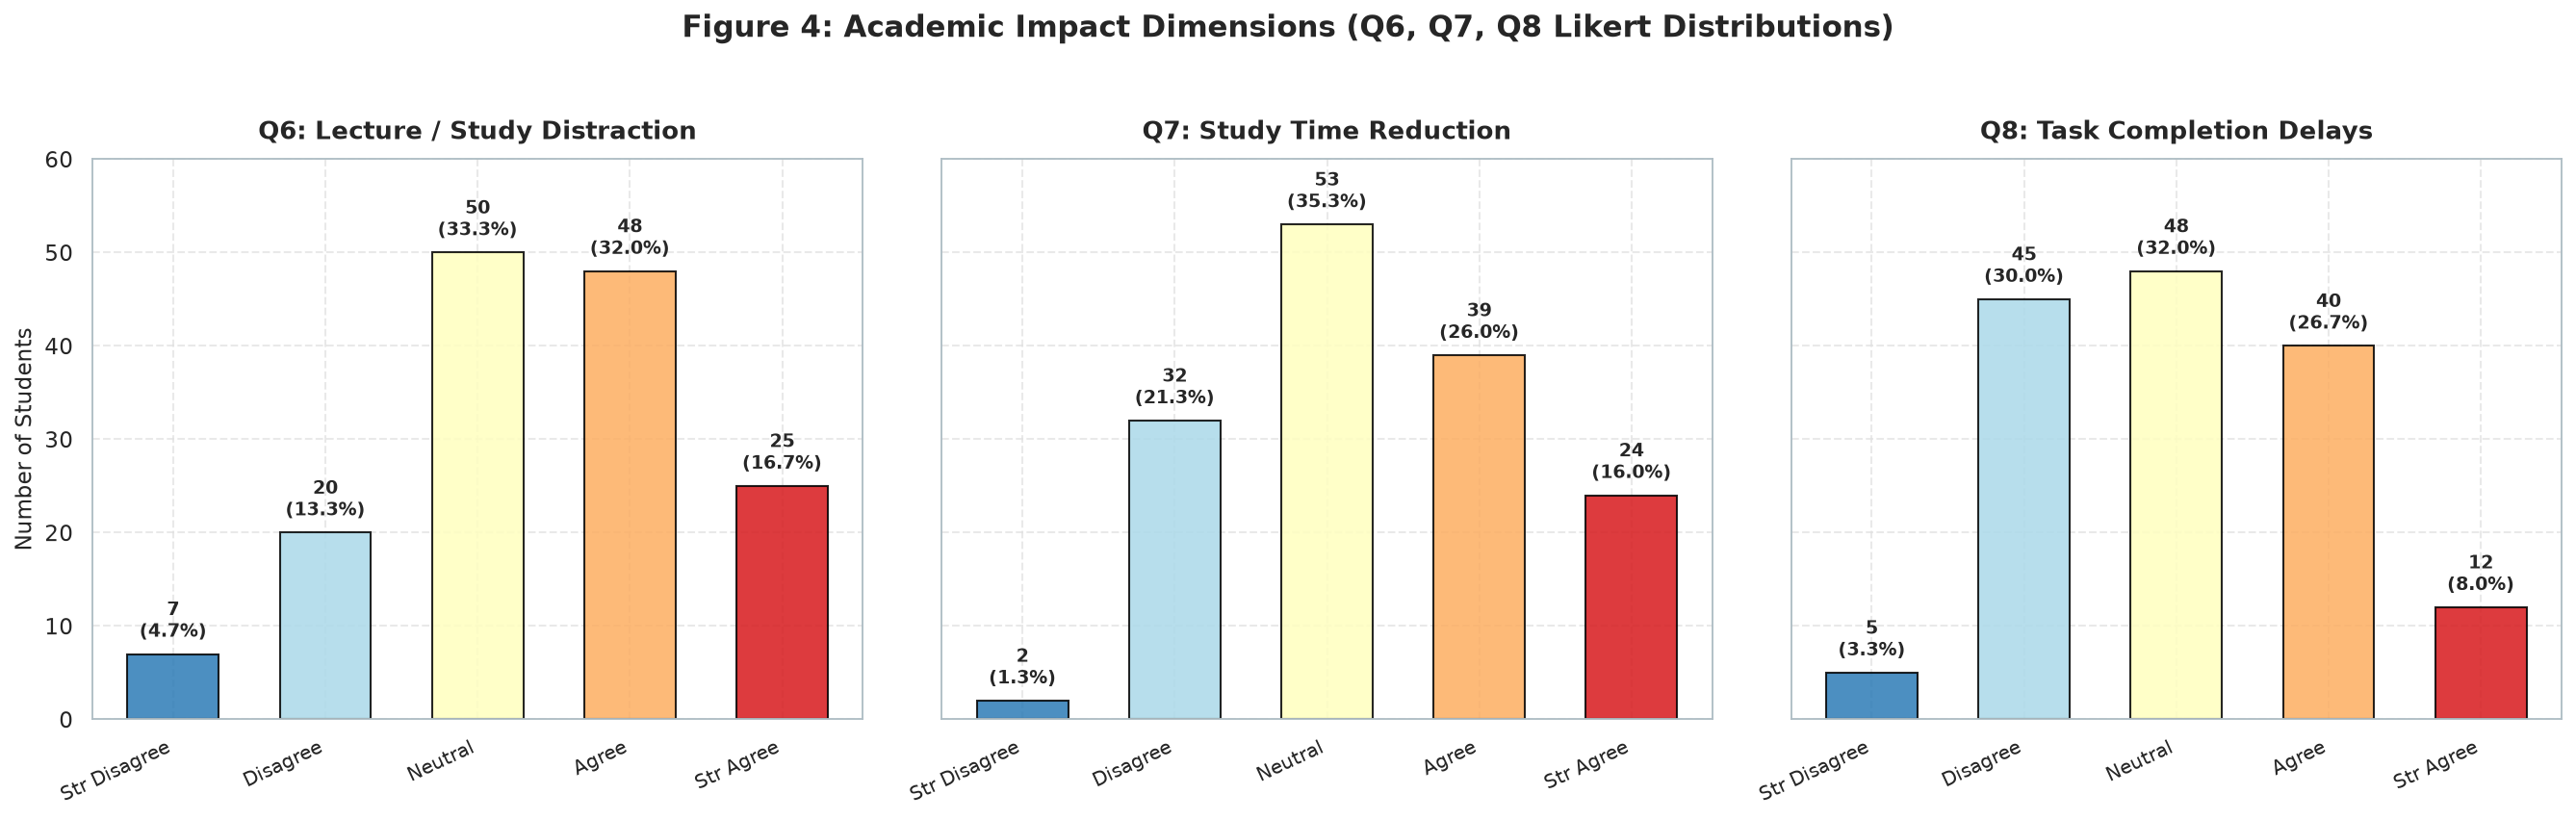

In [15]:
# Cell 15: Academic Impact Questions - Q6, Q7, and Q8
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

likert_order = ['Strongly disagree', 'Disagree', 'Neutral', 'Agree', 'Strongly agree']
likert_labels_short = ['Str Disagree', 'Disagree', 'Neutral', 'Agree', 'Str Agree']
palette_likert = ['#2c7bb6', '#abd9e9', '#ffffbf', '#fdae61', '#d7191c']

academic_items = [
    ('Q6. I get distracted by my smartphone while studying or attending lectures.', 'Q6: Lecture / Study Distraction', axes[0]),
    ('Q7. Using social media, games, or entertainment reduces the time I spend studying.', 'Q7: Study Time Reduction', axes[1]),
    ('Q8. Using digital devices sometimes makes it difficult for me to complete academic tasks on time.', 'Q8: Task Completion Delays', axes[2])
]

for col_name, short_title, ax in academic_items:
    counts = df_comb[col_name].value_counts().reindex(likert_order, fill_value=0)
    pcts = (counts / len(df_comb) * 100).round(1)
    
    bars = ax.bar(range(5), counts.values, color=palette_likert, width=0.6, edgecolor='black', alpha=0.85)
    ax.set_title(short_title, fontsize=12.5, fontweight='bold', pad=10)
    ax.set_xticks(range(5))
    ax.set_xticklabels(likert_labels_short, rotation=25, ha='right', fontsize=9.5)
    ax.set_ylim(0, max(counts.values) * 1.25)
    
    for bar, pct in zip(bars, pcts):
        h = bar.get_height()
        lbl = str(int(h)) + "\n(" + str(pct) + "%)"
        ax.text(bar.get_x() + bar.get_width()/2, h + 1.2, lbl, ha='center', va='bottom', fontsize=9, fontweight='bold')

axes[0].set_ylabel("Number of Students", fontsize=11)
plt.suptitle("Figure 4: Academic Impact Dimensions (Q6, Q7, Q8 Likert Distributions)", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()

fig.savefig(REPORTS_EDA_DIR / '04_academic_impact_q6_q7_q8.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/04_academic_impact_q6_q7_q8.png'), bbox_inches='tight')
plt.show()

**Takeaway:** Lecture distraction (Q6), reduced study time (Q7), and task completion difficulty (Q8) cluster in the neutral-to-agree range.

### 3.5 Social Interaction Interference (Q9–Q11)

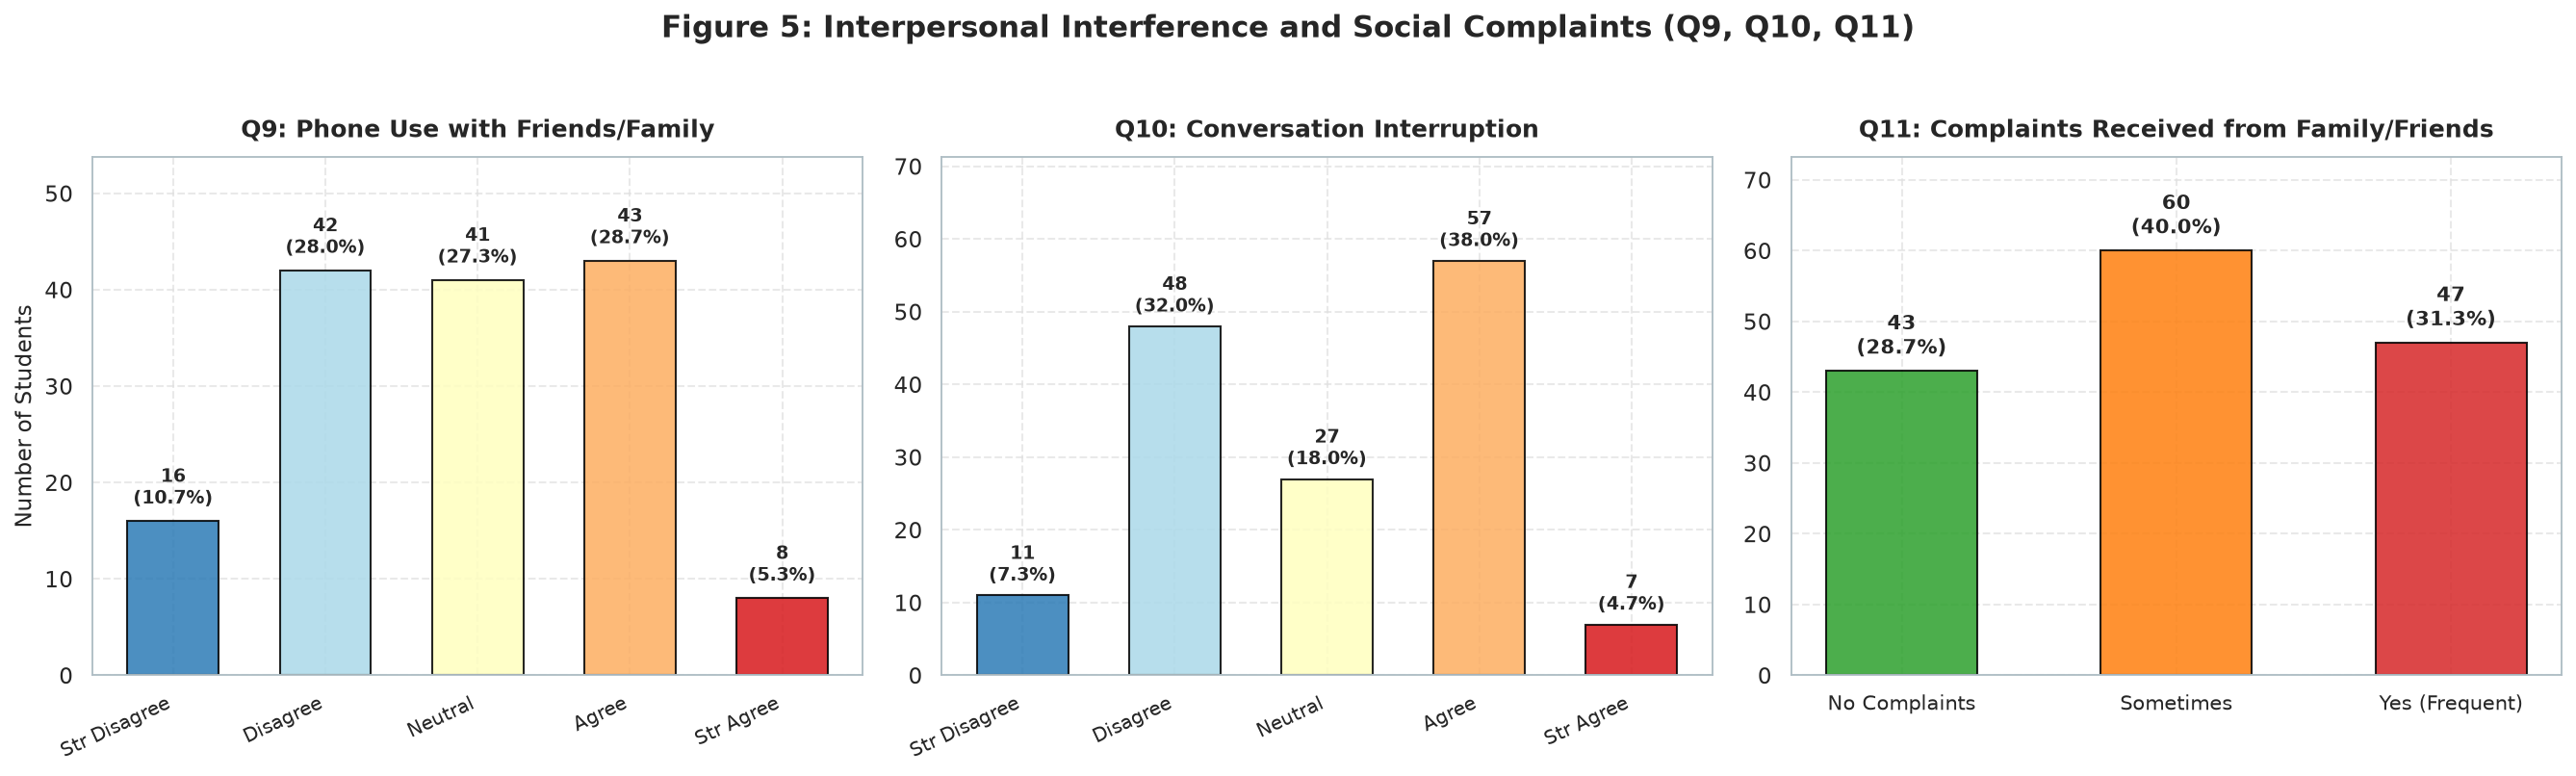

In [16]:
# Cell 16: Social Interaction Questions - Q9, Q10, and Family Complaints Q11
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Q9: Phone with Friends/Family
q9_col = 'Q9. I use my smartphone when spending time with friends or family.'
q9_counts = df_comb[q9_col].value_counts().reindex(likert_order, fill_value=0)
q9_pcts = (q9_counts / len(df_comb) * 100).round(1)

bars_q9 = axes[0].bar(range(5), q9_counts.values, color=palette_likert, width=0.6, edgecolor='black', alpha=0.85)
axes[0].set_title("Q9: Phone Use with Friends/Family", fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel("Number of Students", fontsize=11)
axes[0].set_xticks(range(5))
axes[0].set_xticklabels(likert_labels_short, rotation=25, ha='right', fontsize=9.5)
axes[0].set_ylim(0, max(q9_counts.values) * 1.25)
for bar, pct in zip(bars_q9, q9_pcts):
    h = bar.get_height()
    lbl = str(int(h)) + "\n(" + str(pct) + "%)"
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 1.2, lbl, ha='center', va='bottom', fontsize=9, fontweight='bold')

# Q10: Conversation Interruption
q10_col = 'Q10. Using digital devices sometimes interrupts my face-to-face conversations.'
q10_counts = df_comb[q10_col].value_counts().reindex(likert_order, fill_value=0)
q10_pcts = (q10_counts / len(df_comb) * 100).round(1)

bars_q10 = axes[1].bar(range(5), q10_counts.values, color=palette_likert, width=0.6, edgecolor='black', alpha=0.85)
axes[1].set_title("Q10: Conversation Interruption", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xticks(range(5))
axes[1].set_xticklabels(likert_labels_short, rotation=25, ha='right', fontsize=9.5)
axes[1].set_ylim(0, max(q10_counts.values) * 1.25)
for bar, pct in zip(bars_q10, q10_pcts):
    h = bar.get_height()
    lbl = str(int(h)) + "\n(" + str(pct) + "%)"
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 1.2, lbl, ha='center', va='bottom', fontsize=9, fontweight='bold')

# Q11: Complaints Received
q11_col = 'Q11. Have your friends or family ever complained about your excessive smartphone usage?'
q11_order = ['No', 'Sometimes', 'Yes']
q11_counts = df_comb[q11_col].value_counts().reindex(q11_order, fill_value=0)
q11_pcts = (q11_counts / len(df_comb) * 100).round(1)

bars_q11 = axes[2].bar(q11_order, q11_counts.values, color=['#2ca02c', '#ff7f0e', '#d62728'], width=0.55, edgecolor='black', alpha=0.85)
axes[2].set_title("Q11: Complaints Received from Family/Friends", fontsize=12, fontweight='bold', pad=10)
axes[2].set_xticks(range(3))
axes[2].set_xticklabels(['No Complaints', 'Sometimes', 'Yes (Frequent)'], fontsize=10)
axes[2].set_ylim(0, max(q11_counts.values) * 1.22)
for bar, pct in zip(bars_q11, q11_pcts):
    h = bar.get_height()
    lbl = str(int(h)) + "\n(" + str(pct) + "%)"
    axes[2].text(bar.get_x() + bar.get_width()/2, h + 1.5, lbl, ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle("Figure 5: Interpersonal Interference and Social Complaints (Q9, Q10, Q11)", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()

fig.savefig(REPORTS_EDA_DIR / '05_social_interaction_and_complaints.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/05_social_interaction_and_complaints.png'), bbox_inches='tight')
plt.show()

**Takeaway:** Phone use during family/friend time is common, while formal family complaints remain mostly moderate.

### 3.6 Stay-Away Difficulty (Q12) & Target Class Balance (impact_category)

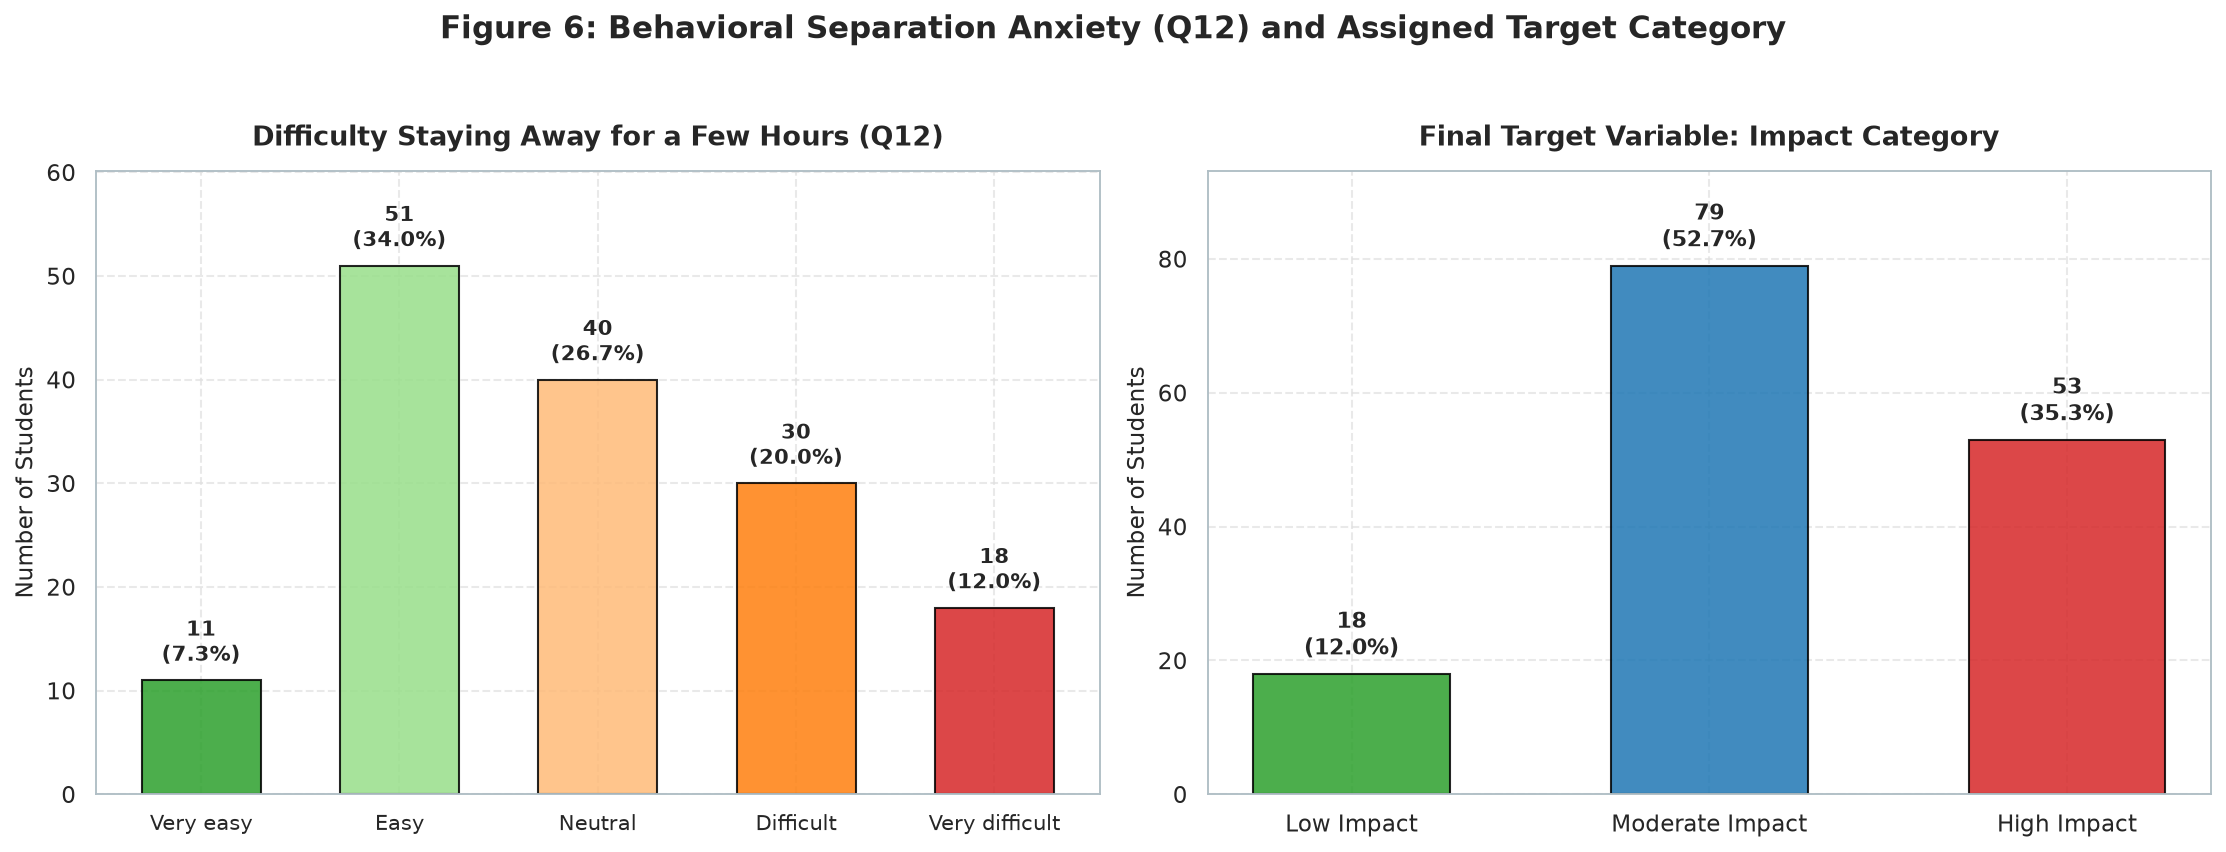

In [17]:
# Cell 17: Separation Difficulty Q12 & Target Impact Category Distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Q12: Stay Away Difficulty
q12_col = 'Q12. How difficult is it for you to stay away from your smartphone for a few hours?'
q12_order = ['Very easy', 'Easy', 'Neutral', 'Difficult', 'Very difficult']
q12_labels = ['Very easy', 'Easy', 'Neutral', 'Difficult', 'Very difficult']
q12_counts = df_comb[q12_col].value_counts().reindex(q12_order, fill_value=0)
q12_pcts = (q12_counts / len(df_comb) * 100).round(1)

colors_q12 = ['#2ca02c', '#98df8a', '#ffbb78', '#ff7f0e', '#d62728']
bars_12 = axes[0].bar(range(5), q12_counts.values, color=colors_q12, width=0.6, edgecolor='black', alpha=0.85)
axes[0].set_title("Difficulty Staying Away for a Few Hours (Q12)", fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel("Number of Students", fontsize=11)
axes[0].set_xticks(range(5))
axes[0].set_xticklabels(q12_labels, fontsize=10)
axes[0].set_ylim(0, max(q12_counts.values) * 1.18)

for bar, pct in zip(bars_12, q12_pcts):
    h = bar.get_height()
    lbl = str(int(h)) + "\n(" + str(pct) + "%)"
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 1.2, lbl, ha='center', va='bottom', fontsize=10, fontweight='bold')

# Target Category Distribution
target_order = ['Low Impact', 'Moderate Impact', 'High Impact']
target_counts = df_comb['impact_category'].value_counts().reindex(target_order, fill_value=0)
target_pcts = (target_counts / len(df_comb) * 100).round(1)

colors_target = [PALETTE_IMPACT[c] for c in target_order]
bars_tgt = axes[1].bar(target_order, target_counts.values, color=colors_target, width=0.55, edgecolor='black', alpha=0.85)
axes[1].set_title("Final Target Variable: Impact Category", fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel("Number of Students", fontsize=11)
axes[1].set_ylim(0, max(target_counts.values) * 1.18)

for bar, pct in zip(bars_tgt, target_pcts):
    h = bar.get_height()
    lbl = str(int(h)) + "\n(" + str(pct) + "%)"
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 1.8, lbl, ha='center', va='bottom', fontsize=10.5, fontweight='bold')

plt.suptitle("Figure 6: Behavioral Separation Anxiety (Q12) and Assigned Target Category", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()

fig.savefig(REPORTS_EDA_DIR / '06_target_impact_category_distribution.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/06_target_impact_category_distribution.png'), bbox_inches='tight')
plt.show()

**Takeaway:** Moderate Impact is the majority class (~53% full / 59% genuine), followed by High Impact, with Low Impact as the smallest minority class (~12–13%).

## 4. Bivariate Analysis

### 4.1 Screen Time vs. Checking Frequency

[CORRELATION] Spearman rank correlation (Screen Time vs. Checking Frequency): r = 0.431 (p = 3.67e-08)


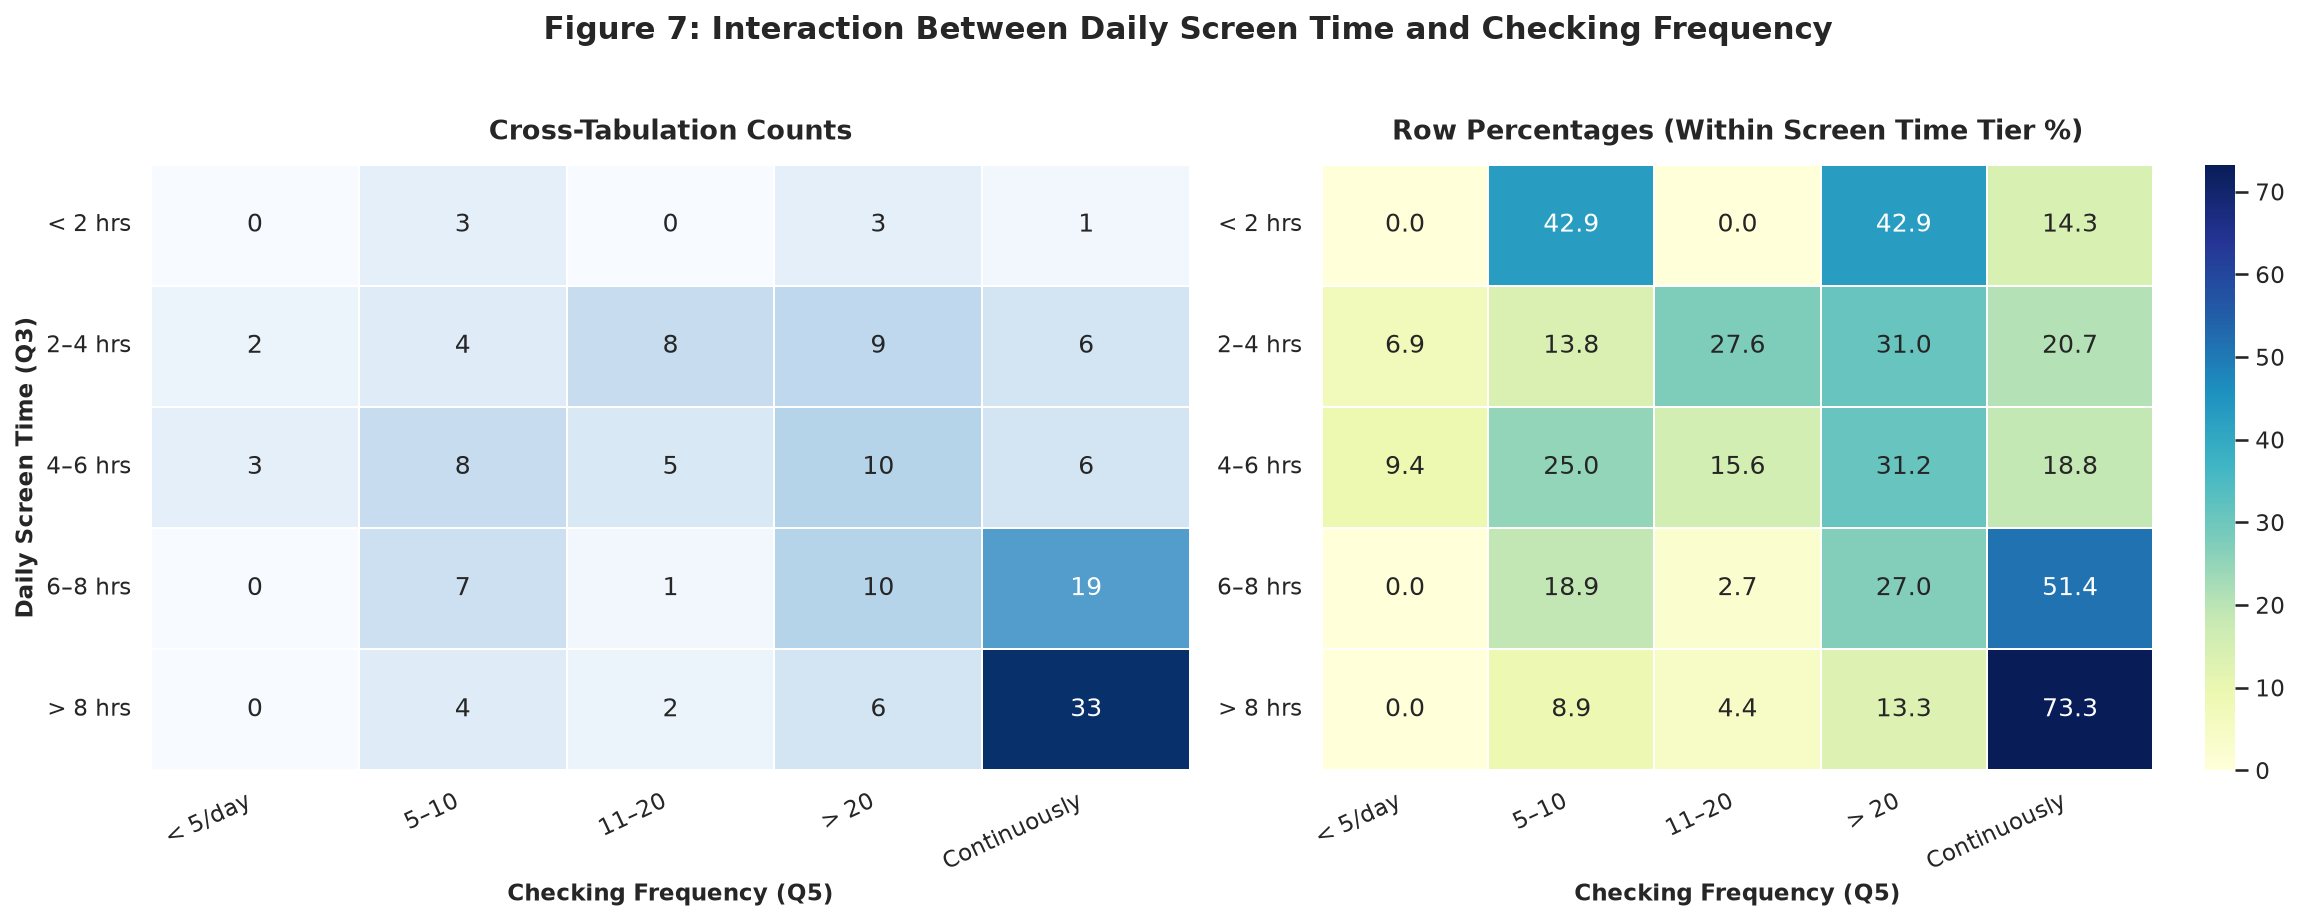

In [18]:
# Cell 18: Screen Time vs Checking Frequency Cross-Tabulation & Heatmap
time_col = 'Q3. How much time do you spend using digital devices daily?'
freq_col = 'Q5. How often do you check your smartphone?'

time_order = ['Less than 2 hours', '2–4 hours', '4–6 hours', '6–8 hours', 'More than 8 hours']
freq_order = ['Less than 5 times a day', '5–10 times a day', '11–20 times a day', 'More than 20 times a day', 'Almost continuously']

ct_time_freq = pd.crosstab(df_comb[time_col], df_comb[freq_col]).reindex(index=time_order, columns=freq_order, fill_value=0)
ct_time_freq_pct = (ct_time_freq.div(ct_time_freq.sum(axis=1), axis=0) * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap of Counts
sns.heatmap(ct_time_freq, ax=axes[0], annot=True, fmt='d', cmap='Blues', cbar=False, linewidths=0.8, linecolor='white')
axes[0].set_title("Cross-Tabulation Counts", fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel("Daily Screen Time (Q3)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Checking Frequency (Q5)", fontsize=11, fontweight='bold')
axes[0].set_yticklabels(['< 2 hrs', '2–4 hrs', '4–6 hrs', '6–8 hrs', '> 8 hrs'], rotation=0)
axes[0].set_xticklabels(['< 5/day', '5–10', '11–20', '> 20', 'Continuously'], rotation=25, ha='right')

# Heatmap of Row Percentages (Within Screen Time Tier)
sns.heatmap(ct_time_freq_pct, ax=axes[1], annot=True, fmt='.1f', cmap='YlGnBu', cbar=True, linewidths=0.8, linecolor='white')
axes[1].set_title("Row Percentages (Within Screen Time Tier %)", fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel("")
axes[1].set_xlabel("Checking Frequency (Q5)", fontsize=11, fontweight='bold')
axes[1].set_yticklabels(['< 2 hrs', '2–4 hrs', '4–6 hrs', '6–8 hrs', '> 8 hrs'], rotation=0)
axes[1].set_xticklabels(['< 5/day', '5–10', '11–20', '> 20', 'Continuously'], rotation=25, ha='right')

plt.suptitle("Figure 7: Interaction Between Daily Screen Time and Checking Frequency", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

fig.savefig(REPORTS_EDA_DIR / '07_bivariate_screentime_vs_checking.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/07_bivariate_screentime_vs_checking.png'), bbox_inches='tight')
plt.show()

# Spearman rank correlation
time_num = df_feat['daily_device_hours']
freq_num = df_feat['check_frequency']
r_tf, p_tf = stats.spearmanr(time_num, freq_num)
print(f"[CORRELATION] Spearman rank correlation (Screen Time vs. Checking Frequency): r = {r_tf:.3f} (p = {p_tf:.2e})")

**Takeaway:** Positive association between daily device hours and smartphone checking frequency.

### 4.2 Screen Time vs. Academic Impact

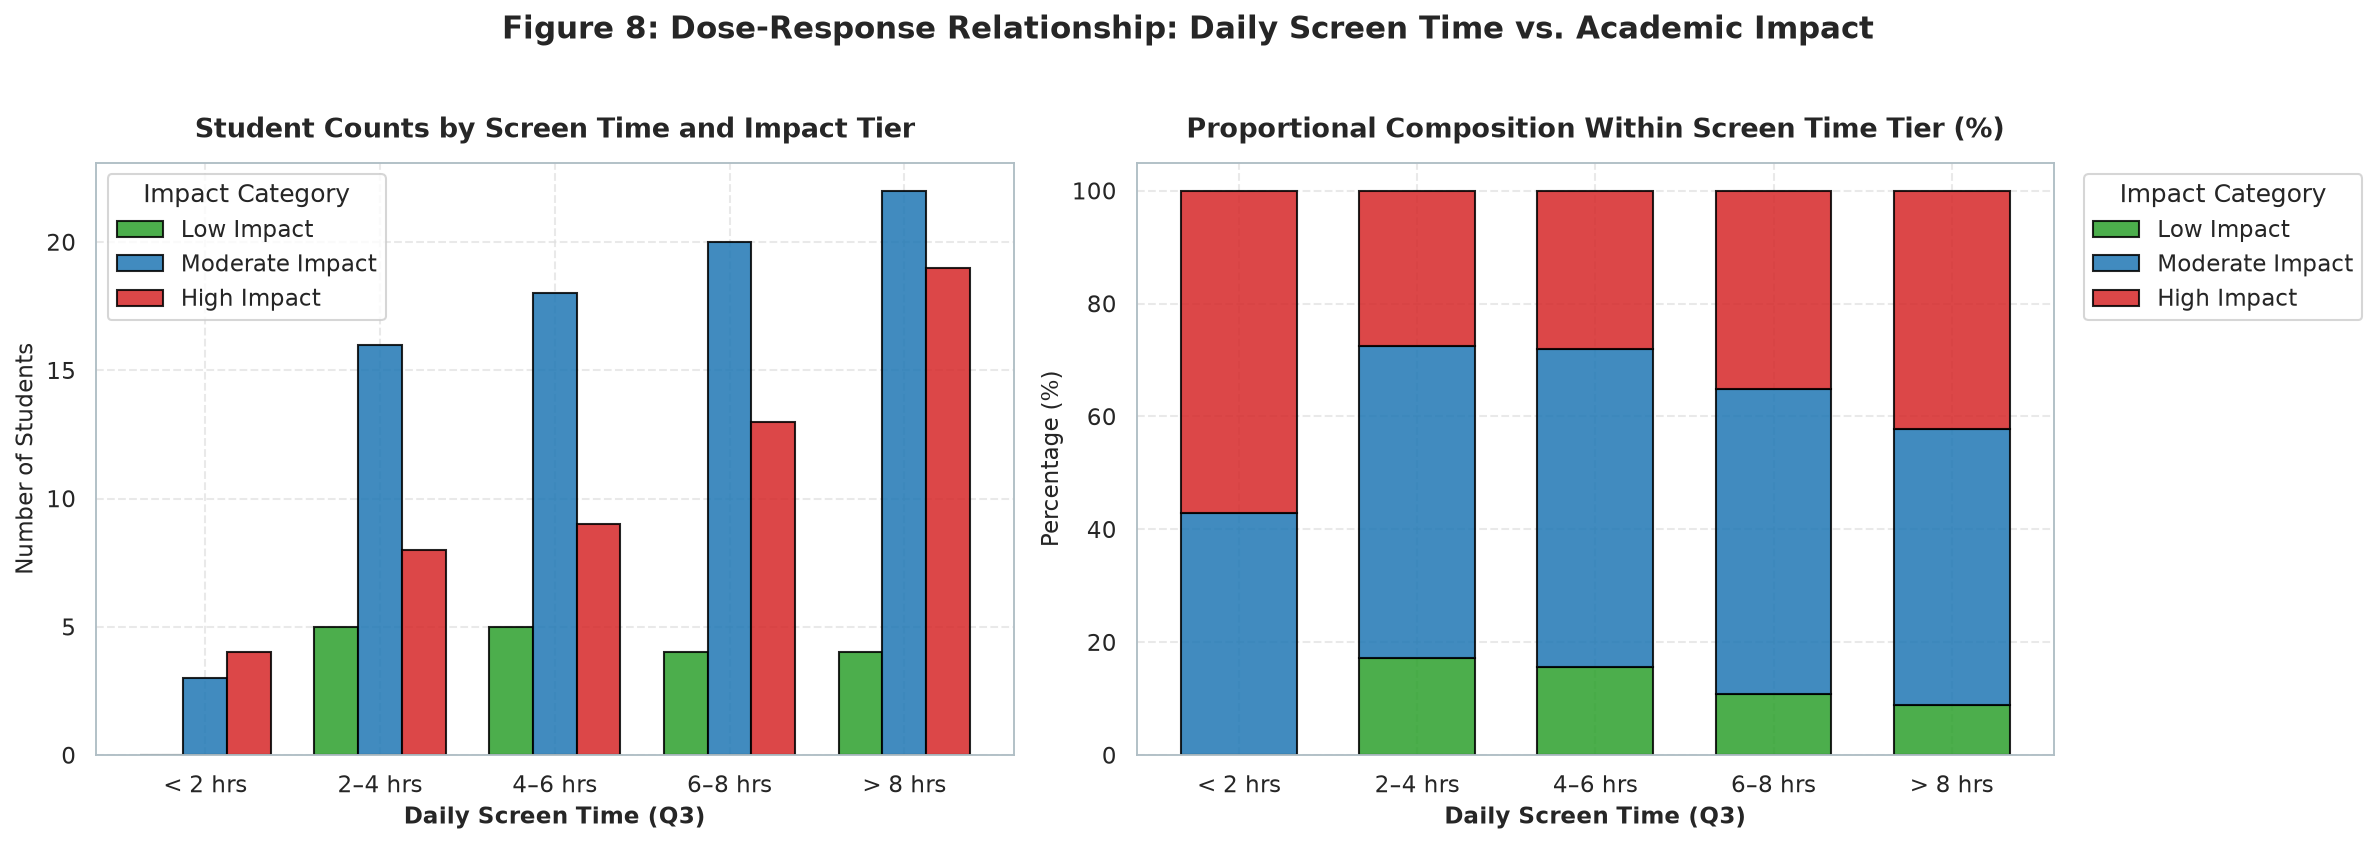

In [19]:
# Cell 19: Screen Time vs Academic Impact Category
ct_time_impact = pd.crosstab(df_comb[time_col], df_comb['impact_category']).reindex(
    index=time_order, 
    columns=['Low Impact', 'Moderate Impact', 'High Impact'], 
    fill_value=0
)
ct_time_impact_pct = ct_time_impact.div(ct_time_impact.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Grouped Count Plot
ct_time_impact.plot(kind='bar', ax=axes[0], color=[PALETTE_IMPACT['Low Impact'], PALETTE_IMPACT['Moderate Impact'], PALETTE_IMPACT['High Impact']], width=0.75, edgecolor='black', alpha=0.85)
axes[0].set_title("Student Counts by Screen Time and Impact Tier", fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel("Number of Students", fontsize=11)
axes[0].set_xlabel("Daily Screen Time (Q3)", fontsize=11, fontweight='bold')
axes[0].set_xticklabels(['< 2 hrs', '2–4 hrs', '4–6 hrs', '6–8 hrs', '> 8 hrs'], rotation=0)
axes[0].legend(title="Impact Category")

# 100% Normalized Stacked Bar Chart
ct_time_impact_pct.plot(kind='bar', stacked=True, ax=axes[1], color=[PALETTE_IMPACT['Low Impact'], PALETTE_IMPACT['Moderate Impact'], PALETTE_IMPACT['High Impact']], width=0.65, edgecolor='black', alpha=0.85)
axes[1].set_title("Proportional Composition Within Screen Time Tier (%)", fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel("Percentage (%)", fontsize=11)
axes[1].set_xlabel("Daily Screen Time (Q3)", fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['< 2 hrs', '2–4 hrs', '4–6 hrs', '6–8 hrs', '> 8 hrs'], rotation=0)
axes[1].legend(title="Impact Category", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.suptitle("Figure 8: Dose-Response Relationship: Daily Screen Time vs. Academic Impact", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

fig.savefig(REPORTS_EDA_DIR / '08_bivariate_screentime_vs_impact.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/08_bivariate_screentime_vs_impact.png'), bbox_inches='tight')
plt.show()

display(ct_time_impact_pct.round(1))

**Takeaway:** Higher screen-time brackets contain a higher proportion of High Impact responses, though overlap exists across all brackets.

### 4.3 Primary Activity vs. Academic Impact

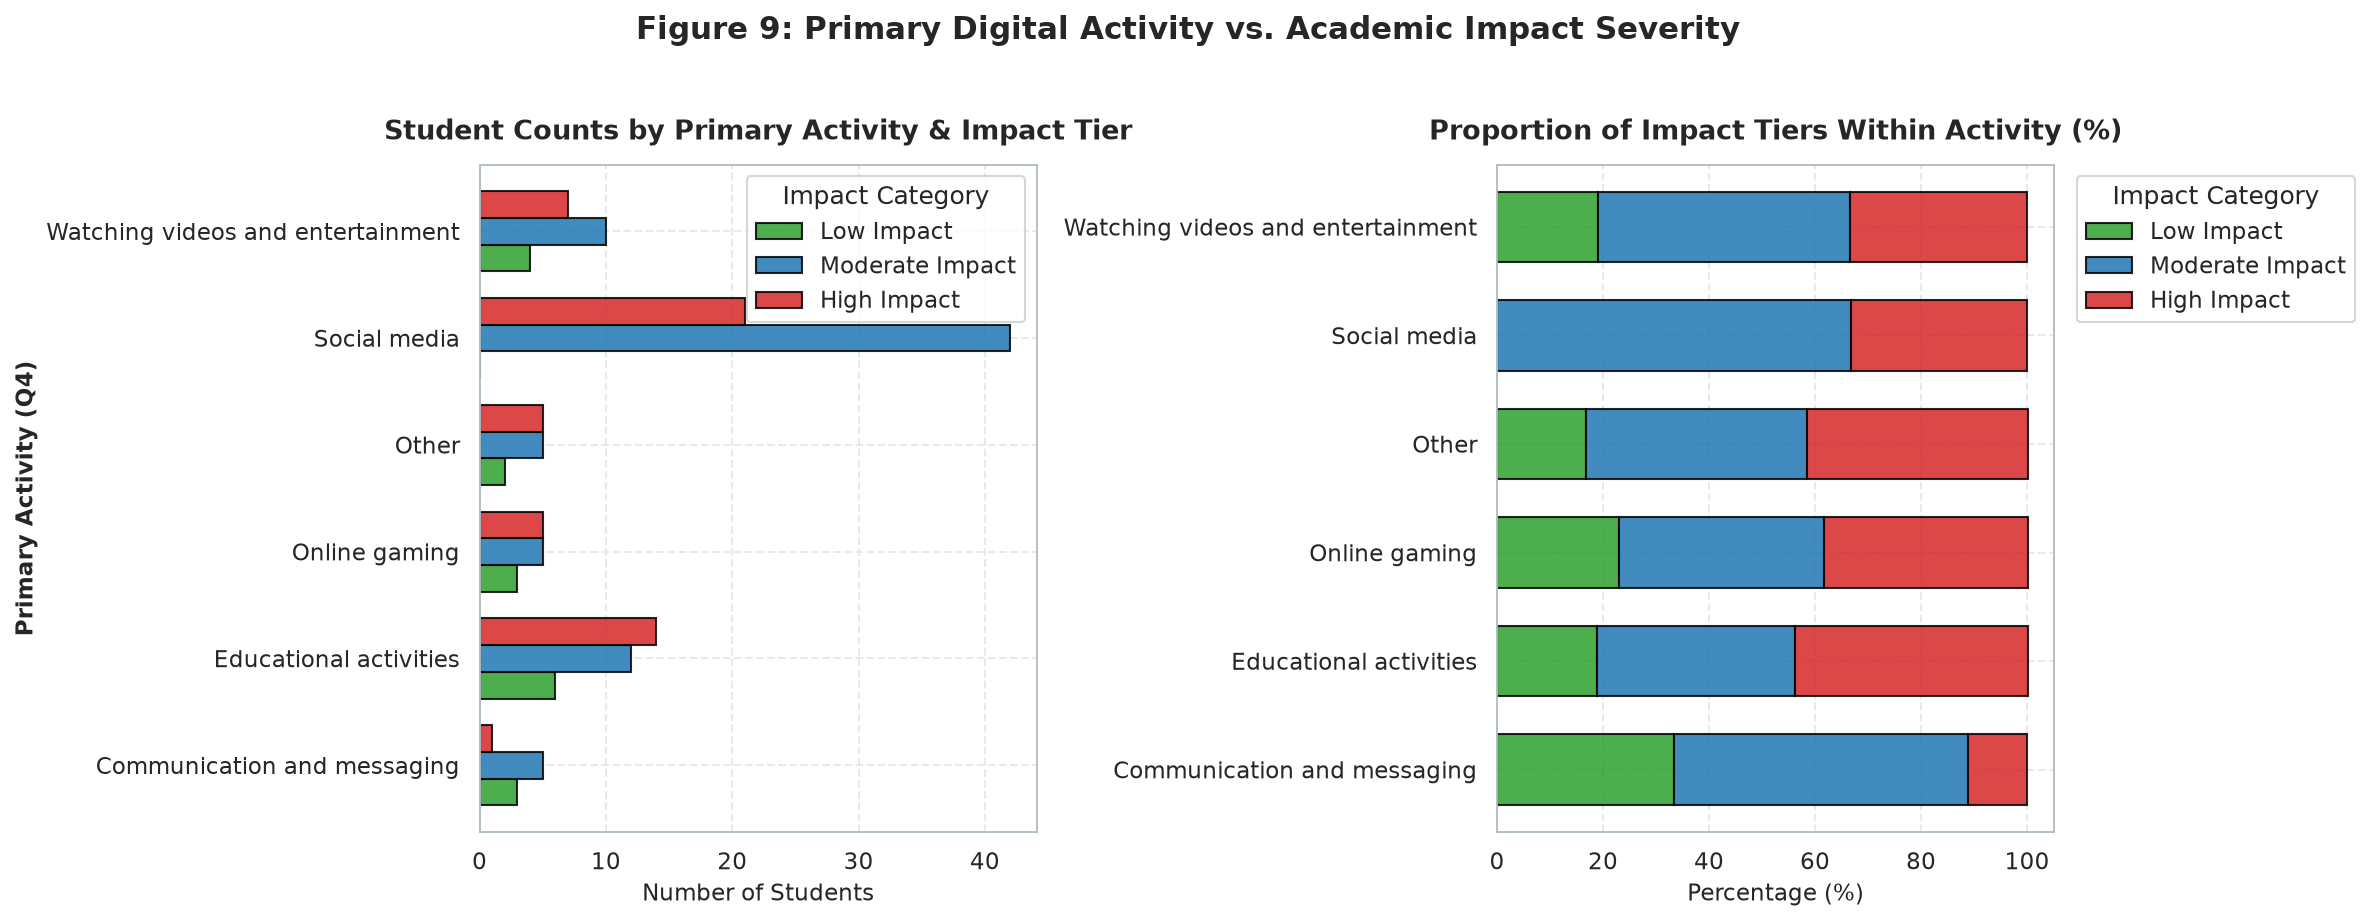

In [20]:
# Cell 20: Primary Activity vs Academic Impact
act_col = 'Q4. Which activity do you use digital devices for the most?'
ct_act_impact = pd.crosstab(df_comb[act_col], df_comb['impact_category']).reindex(
    columns=['Low Impact', 'Moderate Impact', 'High Impact'], 
    fill_value=0
)
ct_act_impact_pct = (ct_act_impact.div(ct_act_impact.sum(axis=1), axis=0) * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grouped Horizontal Bar Chart
ct_act_impact.plot(kind='barh', ax=axes[0], color=[PALETTE_IMPACT['Low Impact'], PALETTE_IMPACT['Moderate Impact'], PALETTE_IMPACT['High Impact']], width=0.75, edgecolor='black', alpha=0.85)
axes[0].set_title("Student Counts by Primary Activity & Impact Tier", fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel("Number of Students", fontsize=11)
axes[0].set_ylabel("Primary Activity (Q4)", fontsize=11, fontweight='bold')
axes[0].legend(title="Impact Category")

# Proportional 100% Stacked Bar Chart
ct_act_impact_pct.plot(kind='barh', stacked=True, ax=axes[1], color=[PALETTE_IMPACT['Low Impact'], PALETTE_IMPACT['Moderate Impact'], PALETTE_IMPACT['High Impact']], width=0.65, edgecolor='black', alpha=0.85)
axes[1].set_title("Proportion of Impact Tiers Within Activity (%)", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Percentage (%)", fontsize=11)
axes[1].set_ylabel("")
axes[1].legend(title="Impact Category", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.suptitle("Figure 9: Primary Digital Activity vs. Academic Impact Severity", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

fig.savefig(REPORTS_EDA_DIR / '09_bivariate_activity_vs_impact.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/09_bivariate_activity_vs_impact.png'), bbox_inches='tight')
plt.show()

display(ct_act_impact_pct)

**Takeaway:** Social media and video entertainment show higher High Impact share than educational activities.

### 4.4 Checking Frequency vs. Stay-Away Difficulty

[CORRELATION] Spearman rank correlation (Checking Frequency vs. Stay Away Difficulty): r = 0.206 (p = 1.14e-02)


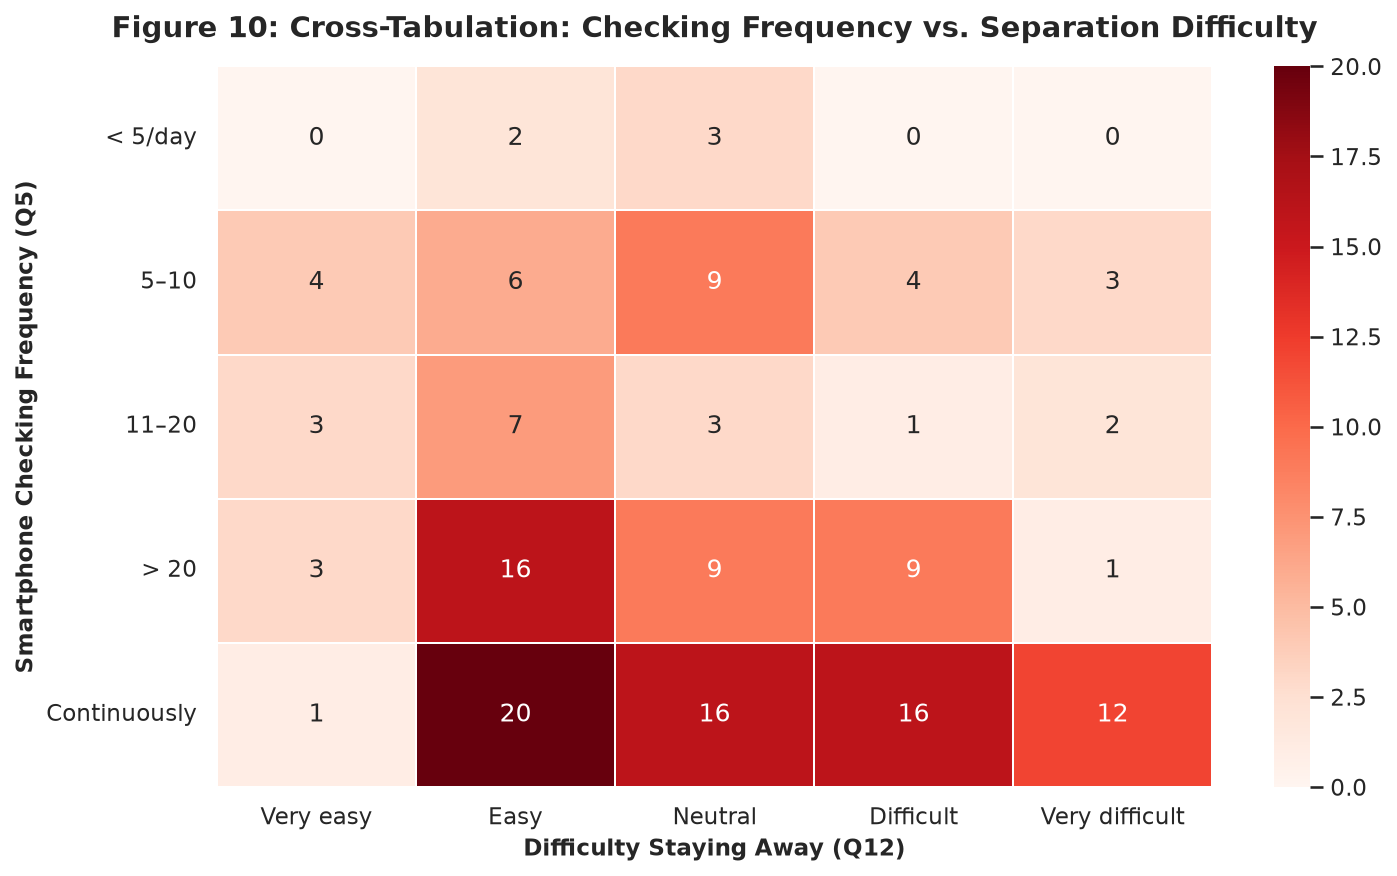

In [21]:
# Cell 21: Checking Frequency vs Stay Away Difficulty
q12_col = 'Q12. How difficult is it for you to stay away from your smartphone for a few hours?'
q12_order = ['Very easy', 'Easy', 'Neutral', 'Difficult', 'Very difficult']

ct_freq_stay = pd.crosstab(df_comb[freq_col], df_comb[q12_col]).reindex(
    index=freq_order, 
    columns=q12_order, 
    fill_value=0
)
ct_freq_stay_pct = (ct_freq_stay.div(ct_freq_stay.sum(axis=1), axis=0) * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(ct_freq_stay, ax=ax, annot=True, fmt='d', cmap='Reds', cbar=True, linewidths=0.8, linecolor='white')
ax.set_title("Figure 10: Cross-Tabulation: Checking Frequency vs. Separation Difficulty", fontsize=14, fontweight='bold', pad=14)
ax.set_ylabel("Smartphone Checking Frequency (Q5)", fontsize=11, fontweight='bold')
ax.set_xlabel("Difficulty Staying Away (Q12)", fontsize=11, fontweight='bold')
ax.set_yticklabels(['< 5/day', '5–10', '11–20', '> 20', 'Continuously'], rotation=0)

plt.tight_layout()
fig.savefig(REPORTS_EDA_DIR / '10_bivariate_checking_vs_stayaway.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/10_bivariate_checking_vs_stayaway.png'), bbox_inches='tight')
plt.show()

r_fs, p_fs = stats.spearmanr(df_feat['check_frequency'], df_feat['stay_away_difficulty'])
print(f"[CORRELATION] Spearman rank correlation (Checking Frequency vs. Stay Away Difficulty): r = {r_fs:.3f} (p = {p_fs:.2e})")

**Takeaway:** Frequent phone checking correlates positively with difficulty staying detached from devices.

### 4.5 Social Conflict Score vs. Academic Impact

[STAT TEST] Kruskal-Wallis test for Social Conflict Score across Impact Categories: H = 47.836, p = 4.10e-11


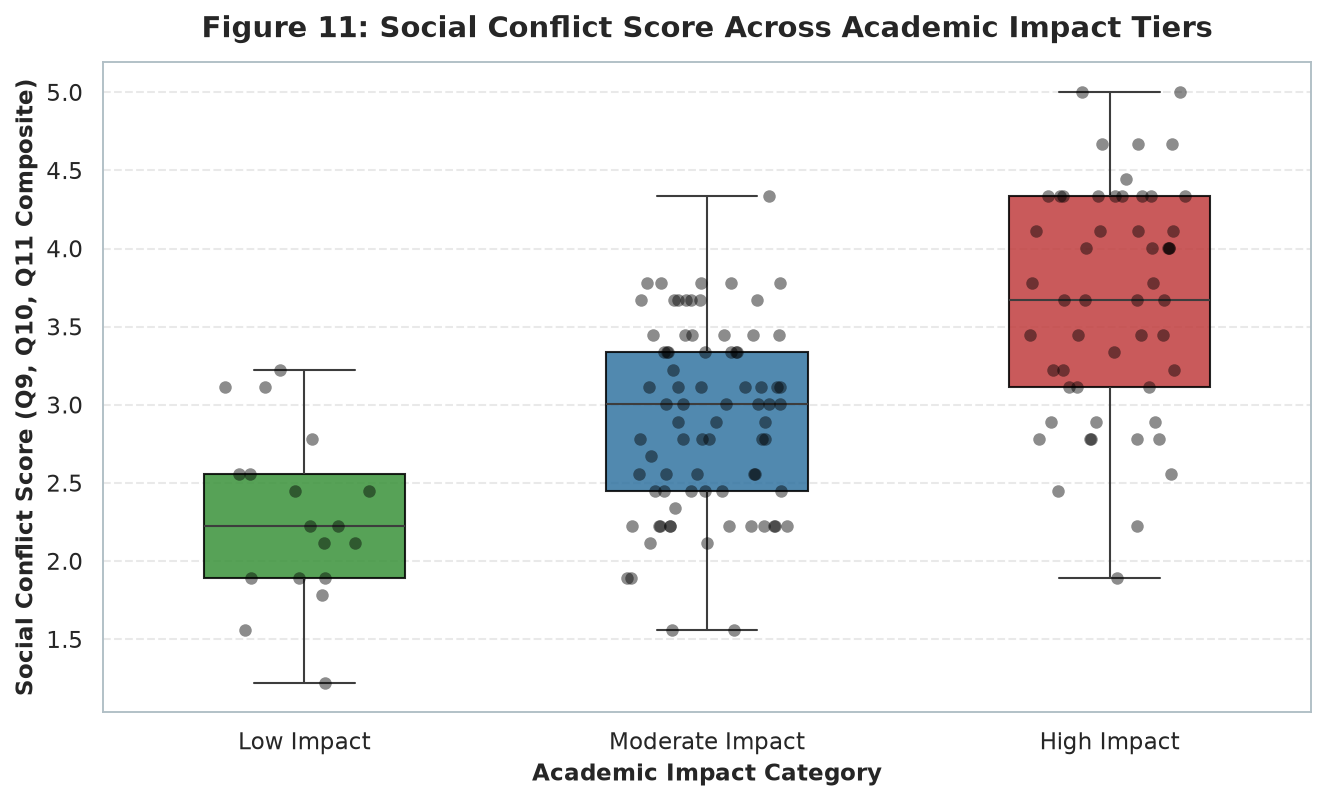

In [22]:
# Cell 22: Social Disruption Score vs Academic Impact Category
fig, ax = plt.subplots(figsize=(9, 5.5))

sns.boxplot(
    data=df_feat, 
    x='impact_category', 
    y='social_conflict_score', 
    order=['Low Impact', 'Moderate Impact', 'High Impact'], 
    palette=PALETTE_IMPACT, 
    width=0.5, 
    boxprops=dict(alpha=0.85, edgecolor='black'),
    ax=ax
)
sns.stripplot(
    data=df_feat, 
    x='impact_category', 
    y='social_conflict_score', 
    order=['Low Impact', 'Moderate Impact', 'High Impact'], 
    color='black', 
    alpha=0.45, 
    jitter=0.2, 
    size=6, 
    ax=ax
)

ax.set_title("Figure 11: Social Conflict Score Across Academic Impact Tiers", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Academic Impact Category", fontsize=11, fontweight='bold')
ax.set_ylabel("Social Conflict Score (Q9, Q10, Q11 Composite)", fontsize=11, fontweight='bold')

plt.tight_layout()
fig.savefig(REPORTS_EDA_DIR / '11_bivariate_social_disruption_vs_impact.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/11_bivariate_social_disruption_vs_impact.png'), bbox_inches='tight')
plt.show()

# ANOVA / Kruskal-Wallis across impact tiers
groups_soc = [group['social_conflict_score'].values for _, group in df_feat.groupby('impact_category')]
h_stat, p_val = stats.kruskal(*groups_soc)
print(f"[STAT TEST] Kruskal-Wallis test for Social Conflict Score across Impact Categories: H = {h_stat:.3f}, p = {p_val:.2e}")

**Takeaway:** Higher interpersonal friction tends to co-occur with higher perceived academic impact.

### 4.6 Digital Dependency Score vs. Academic Impact

[STAT TEST] Kruskal-Wallis test for Digital Dependency Score across Impact Categories: H = 19.822, p = 4.96e-05


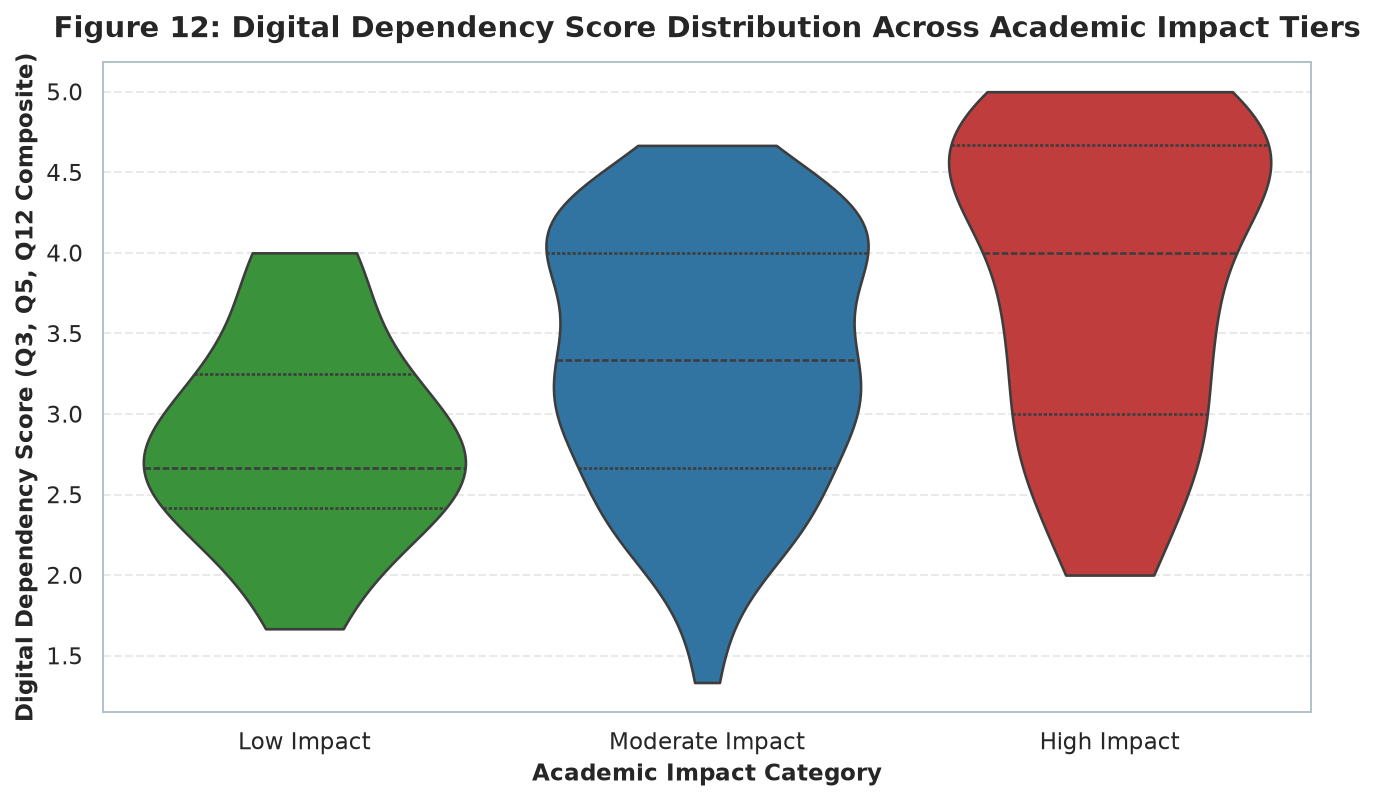

In [23]:
# Cell 23: Digital Dependency Score Across Impact Categories
fig, ax = plt.subplots(figsize=(9, 5.5))

sns.violinplot(
    data=df_feat, 
    x='impact_category', 
    y='digital_dependency_score', 
    order=['Low Impact', 'Moderate Impact', 'High Impact'], 
    palette=PALETTE_IMPACT, 
    inner='quartile', 
    cut=0, 
    ax=ax
)

ax.set_title("Figure 12: Digital Dependency Score Distribution Across Academic Impact Tiers", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Academic Impact Category", fontsize=11, fontweight='bold')
ax.set_ylabel("Digital Dependency Score (Q3, Q5, Q12 Composite)", fontsize=11, fontweight='bold')

plt.tight_layout()
fig.savefig(REPORTS_EDA_DIR / '12_bivariate_digital_dependency_vs_impact.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/12_bivariate_digital_dependency_vs_impact.png'), bbox_inches='tight')
plt.show()

dep_summary = df_feat.groupby('impact_category')['digital_dependency_score'].agg(['count', 'mean', 'std', 'median']).reindex(['Low Impact', 'Moderate Impact', 'High Impact'])
display(dep_summary.round(3))

groups_dep = [group['digital_dependency_score'].values for _, group in df_feat.groupby('impact_category')]
h_dep, p_dep = stats.kruskal(*groups_dep)
print(f"[STAT TEST] Kruskal-Wallis test for Digital Dependency Score across Impact Categories: H = {h_dep:.3f}, p = {p_dep:.2e}")

**Takeaway:** Mean digital dependency increases across impact tiers, with substantial within-class spread.

## 5. Numerical Feature Distributions, Outliers & Correlation

### 5.1 Feature Histograms

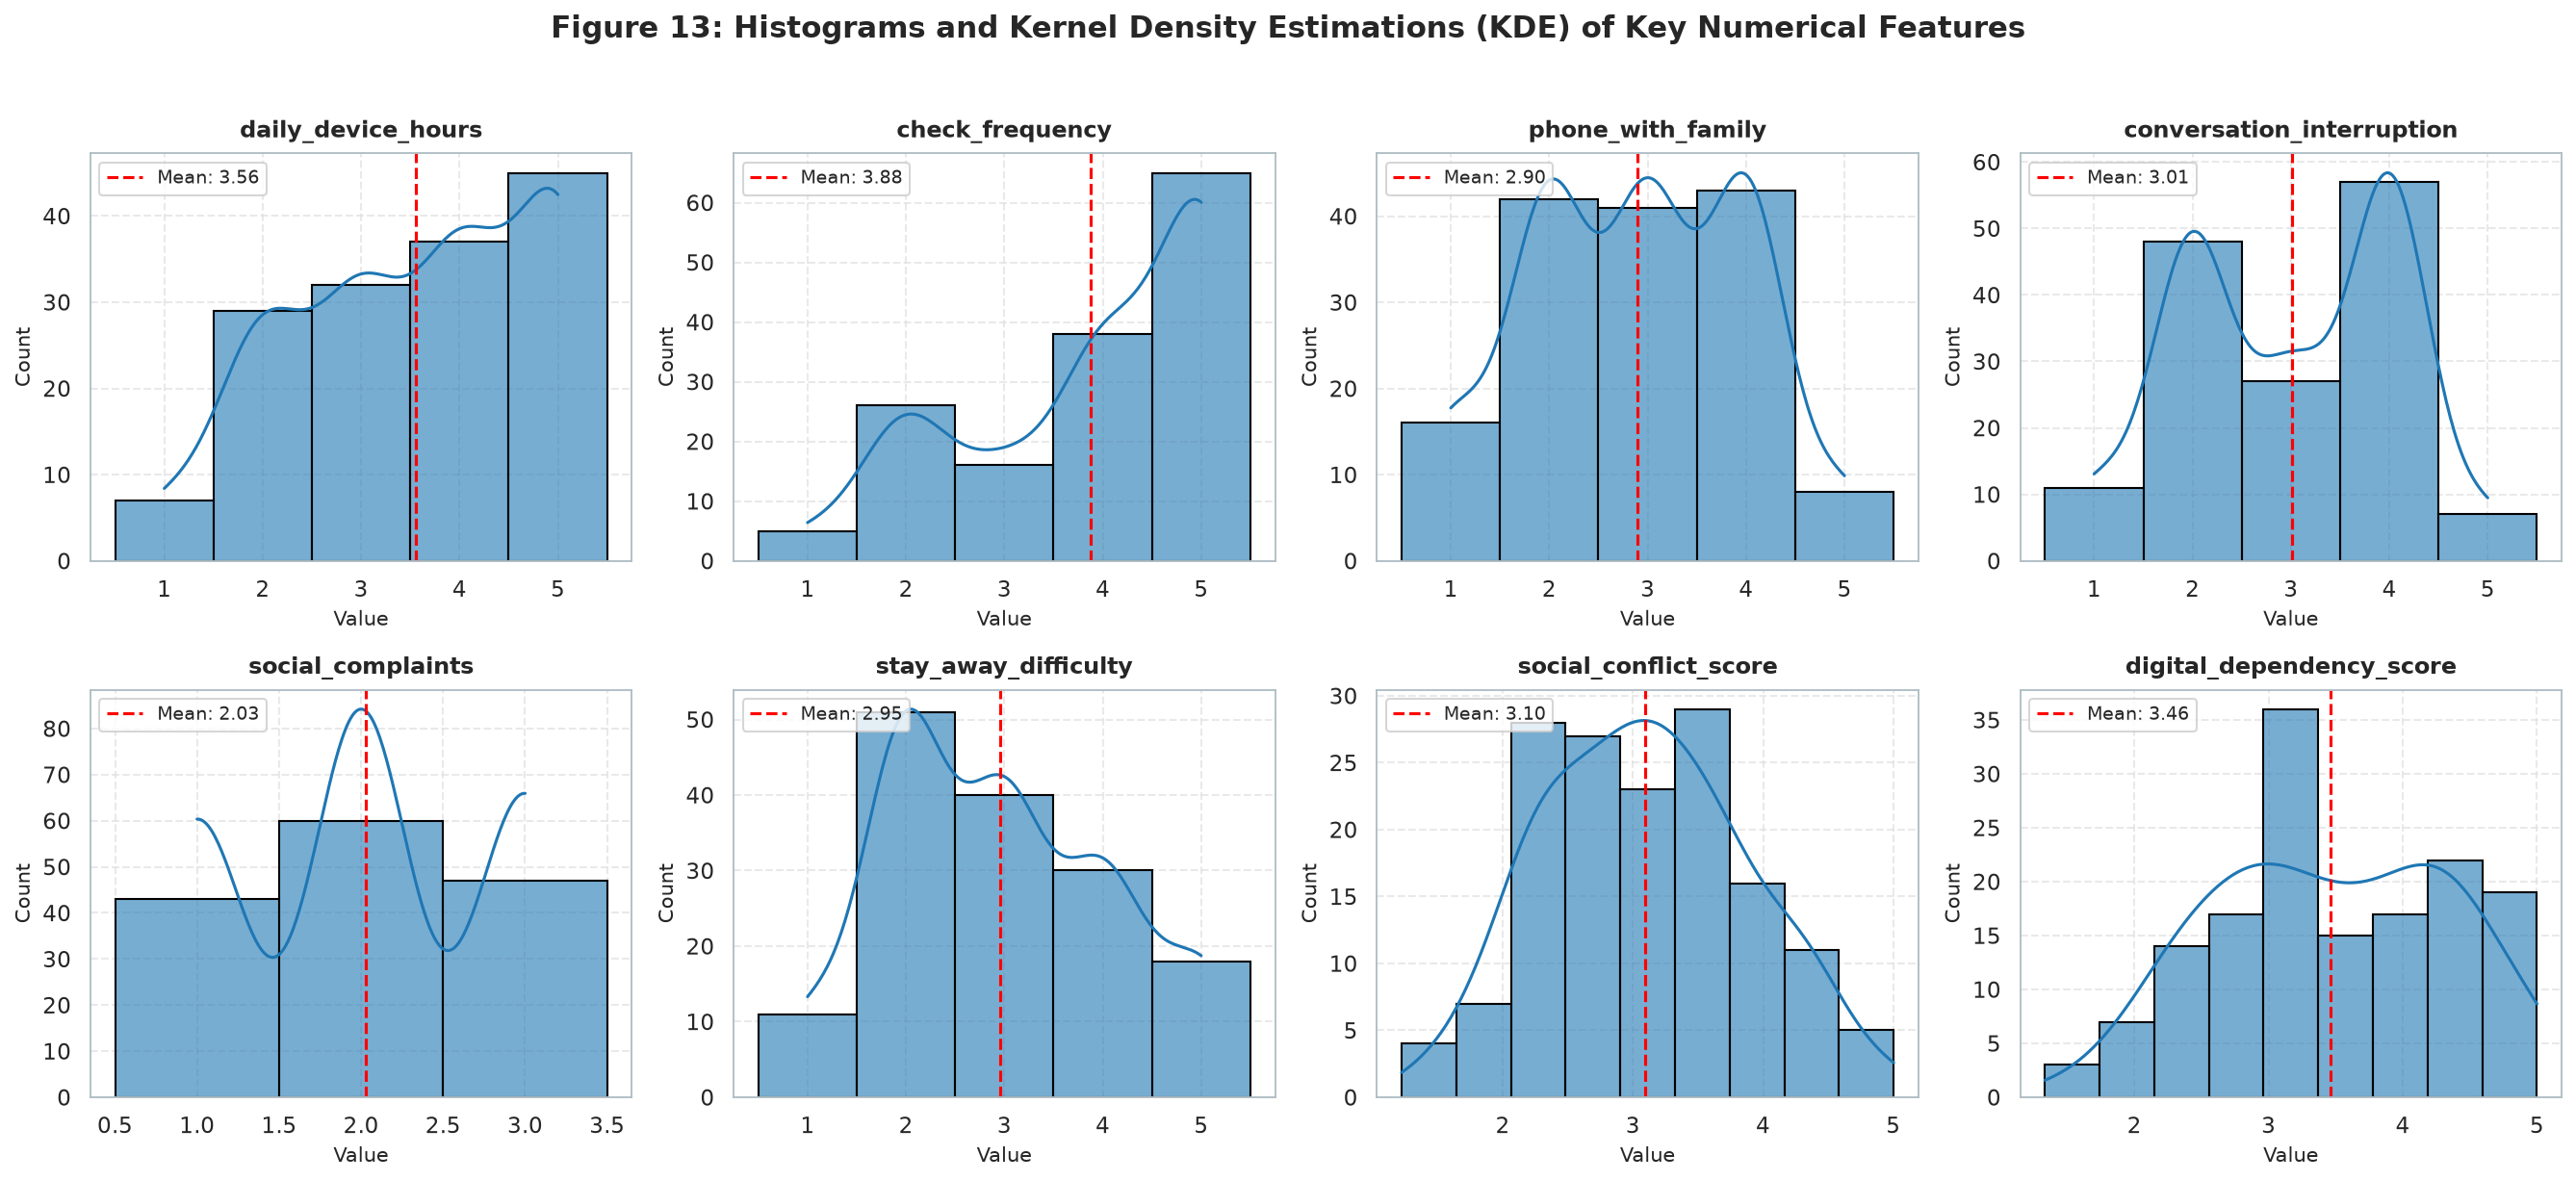

In [24]:
# Cell 24: Histograms and KDE Plots for Numerical Input Features
numeric_input_features = [
    'daily_device_hours', 'check_frequency', 'phone_with_family', 
    'conversation_interruption', 'social_complaints', 'stay_away_difficulty',
    'social_conflict_score', 'digital_dependency_score'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for idx, feat in enumerate(numeric_input_features):
    ax = axes[idx]
    sns.histplot(
        df_feat[feat], 
        kde=True, 
        ax=ax, 
        color='#1f77b4', 
        edgecolor='black', 
        alpha=0.6,
        discrete=(feat not in ['social_conflict_score', 'digital_dependency_score'])
    )
    ax.set_title(f"{feat}", fontsize=11.5, fontweight='bold', pad=8)
    ax.set_xlabel("Value", fontsize=10)
    ax.set_ylabel("Count", fontsize=10)
    
    # Annotate mean and std
    mu = df_feat[feat].mean()
    sigma = df_feat[feat].std()
    ax.axvline(mu, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mu:.2f}')
    ax.legend(fontsize=9, loc='upper left')

plt.suptitle("Figure 13: Histograms and Kernel Density Estimations (KDE) of Key Numerical Features", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

fig.savefig(REPORTS_EDA_DIR / '13_numerical_feature_distributions.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/13_numerical_feature_distributions.png'), bbox_inches='tight')
plt.show()

**Takeaway:** Bounded Likert items show mild skew toward higher usage and checking ratings.

### 5.2 Outlier Detection via Box Plots (IQR)

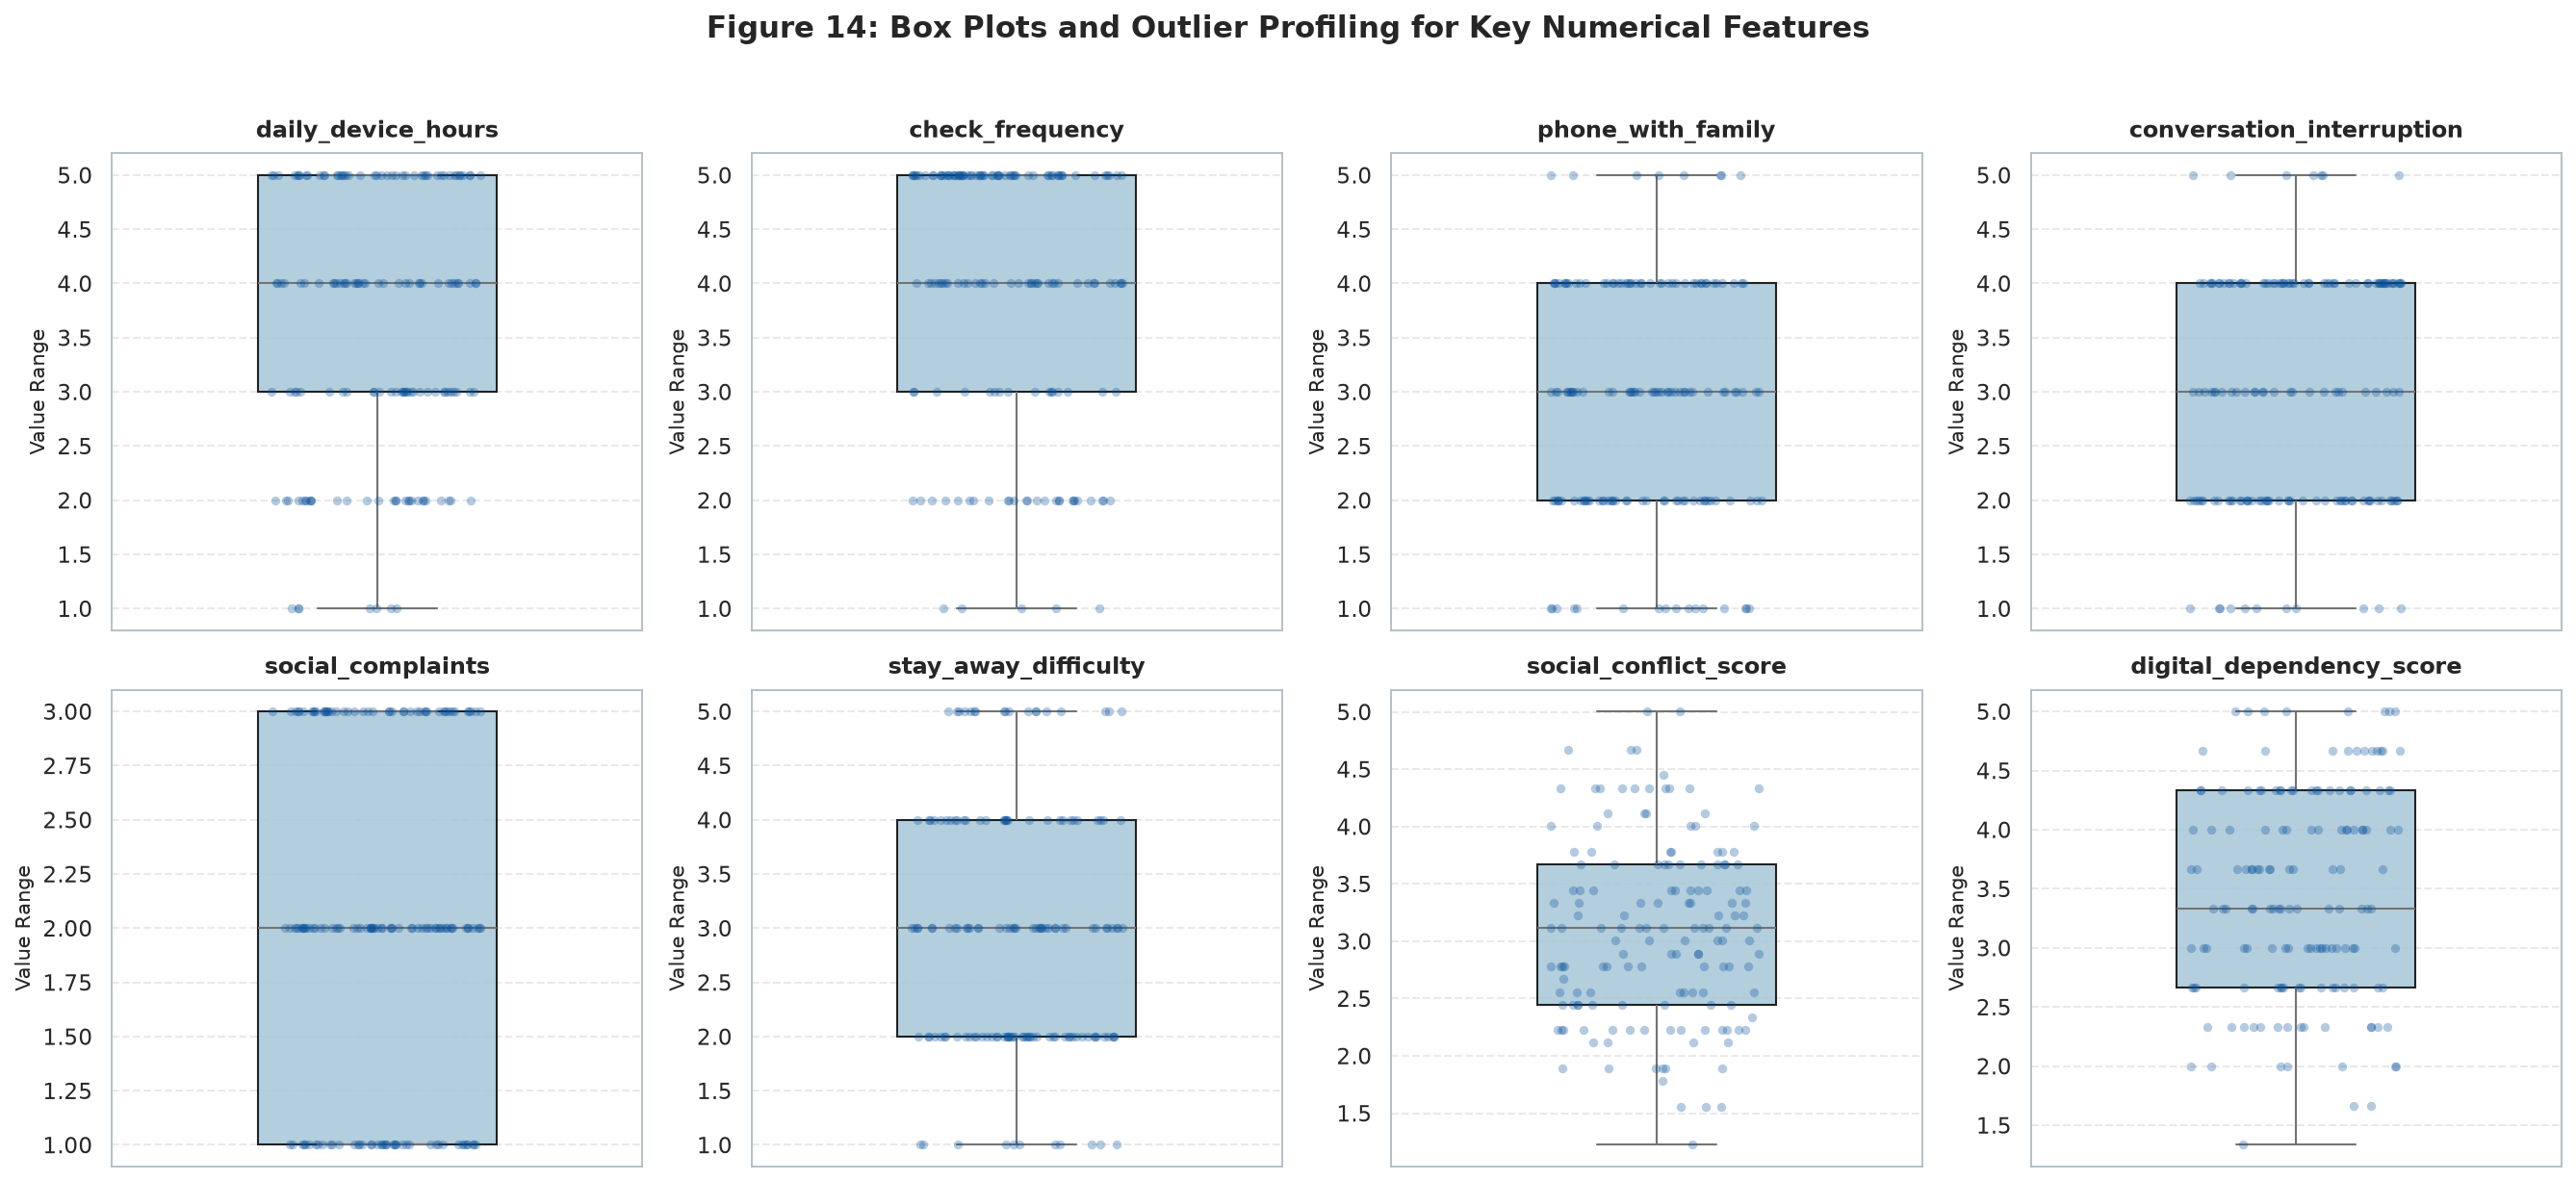

,Feature,Q25,Q75,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,daily_device_hours,3.00,5.00,2.00,0.00,8.00,0,0.0
1,check_frequency,3.00,5.00,2.00,0.00,8.00,0,0.0
2,phone_with_family,2.00,4.00,2.00,-1.00,7.00,0,0.0
3,conversation_interruption,2.00,4.00,2.00,-1.00,7.00,0,0.0
4,social_complaints,1.00,3.00,2.00,-2.00,6.00,0,0.0
5,stay_away_difficulty,2.00,4.00,2.00,-1.00,7.00,0,0.0
6,social_conflict_score,2.45,3.67,1.22,0.61,5.50,0,0.0
7,digital_dependency_score,2.67,4.33,1.67,0.17,6.83,0,0.0


In [25]:
# Cell 25: Box Plots for Numerical Input Features
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for idx, feat in enumerate(numeric_input_features):
    ax = axes[idx]
    sns.boxplot(
        y=df_feat[feat], 
        ax=ax, 
        color='#9ecae1', 
        width=0.45, 
        boxprops=dict(edgecolor='black', alpha=0.85),
        flierprops=dict(marker='o', markerfacecolor='red', markersize=6, linestyle='none')
    )
    sns.stripplot(
        y=df_feat[feat], 
        ax=ax, 
        color='#08519c', 
        alpha=0.3, 
        jitter=0.2, 
        size=4.5
    )
    ax.set_title(f"{feat}", fontsize=11.5, fontweight='bold', pad=8)
    ax.set_ylabel("Value Range", fontsize=10)

plt.suptitle("Figure 14: Box Plots and Outlier Profiling for Key Numerical Features", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

fig.savefig(REPORTS_EDA_DIR / '14_numerical_feature_boxplots.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/14_numerical_feature_boxplots.png'), bbox_inches='tight')
plt.show()

# Quantitative outlier detection using 1.5 * IQR rule
outlier_records = []
for feat in numeric_input_features:
    q25 = df_feat[feat].quantile(0.25)
    q75 = df_feat[feat].quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr
    outliers = df_feat[(df_feat[feat] < lower_bound) | (df_feat[feat] > upper_bound)]
    outlier_records.append({
        'Feature': feat,
        'Q25': round(q25, 2),
        'Q75': round(q75, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': len(outliers),
        'Outlier %': round(len(outliers) / len(df_feat) * 100, 2)
    })

pd.DataFrame(outlier_records)

**Takeaway:** Because survey scales are bounded $[1, 5]$, no invalid or extreme numerical outliers require removal.

### 5.3 Spearman Correlation Heatmap (Input Features Only)

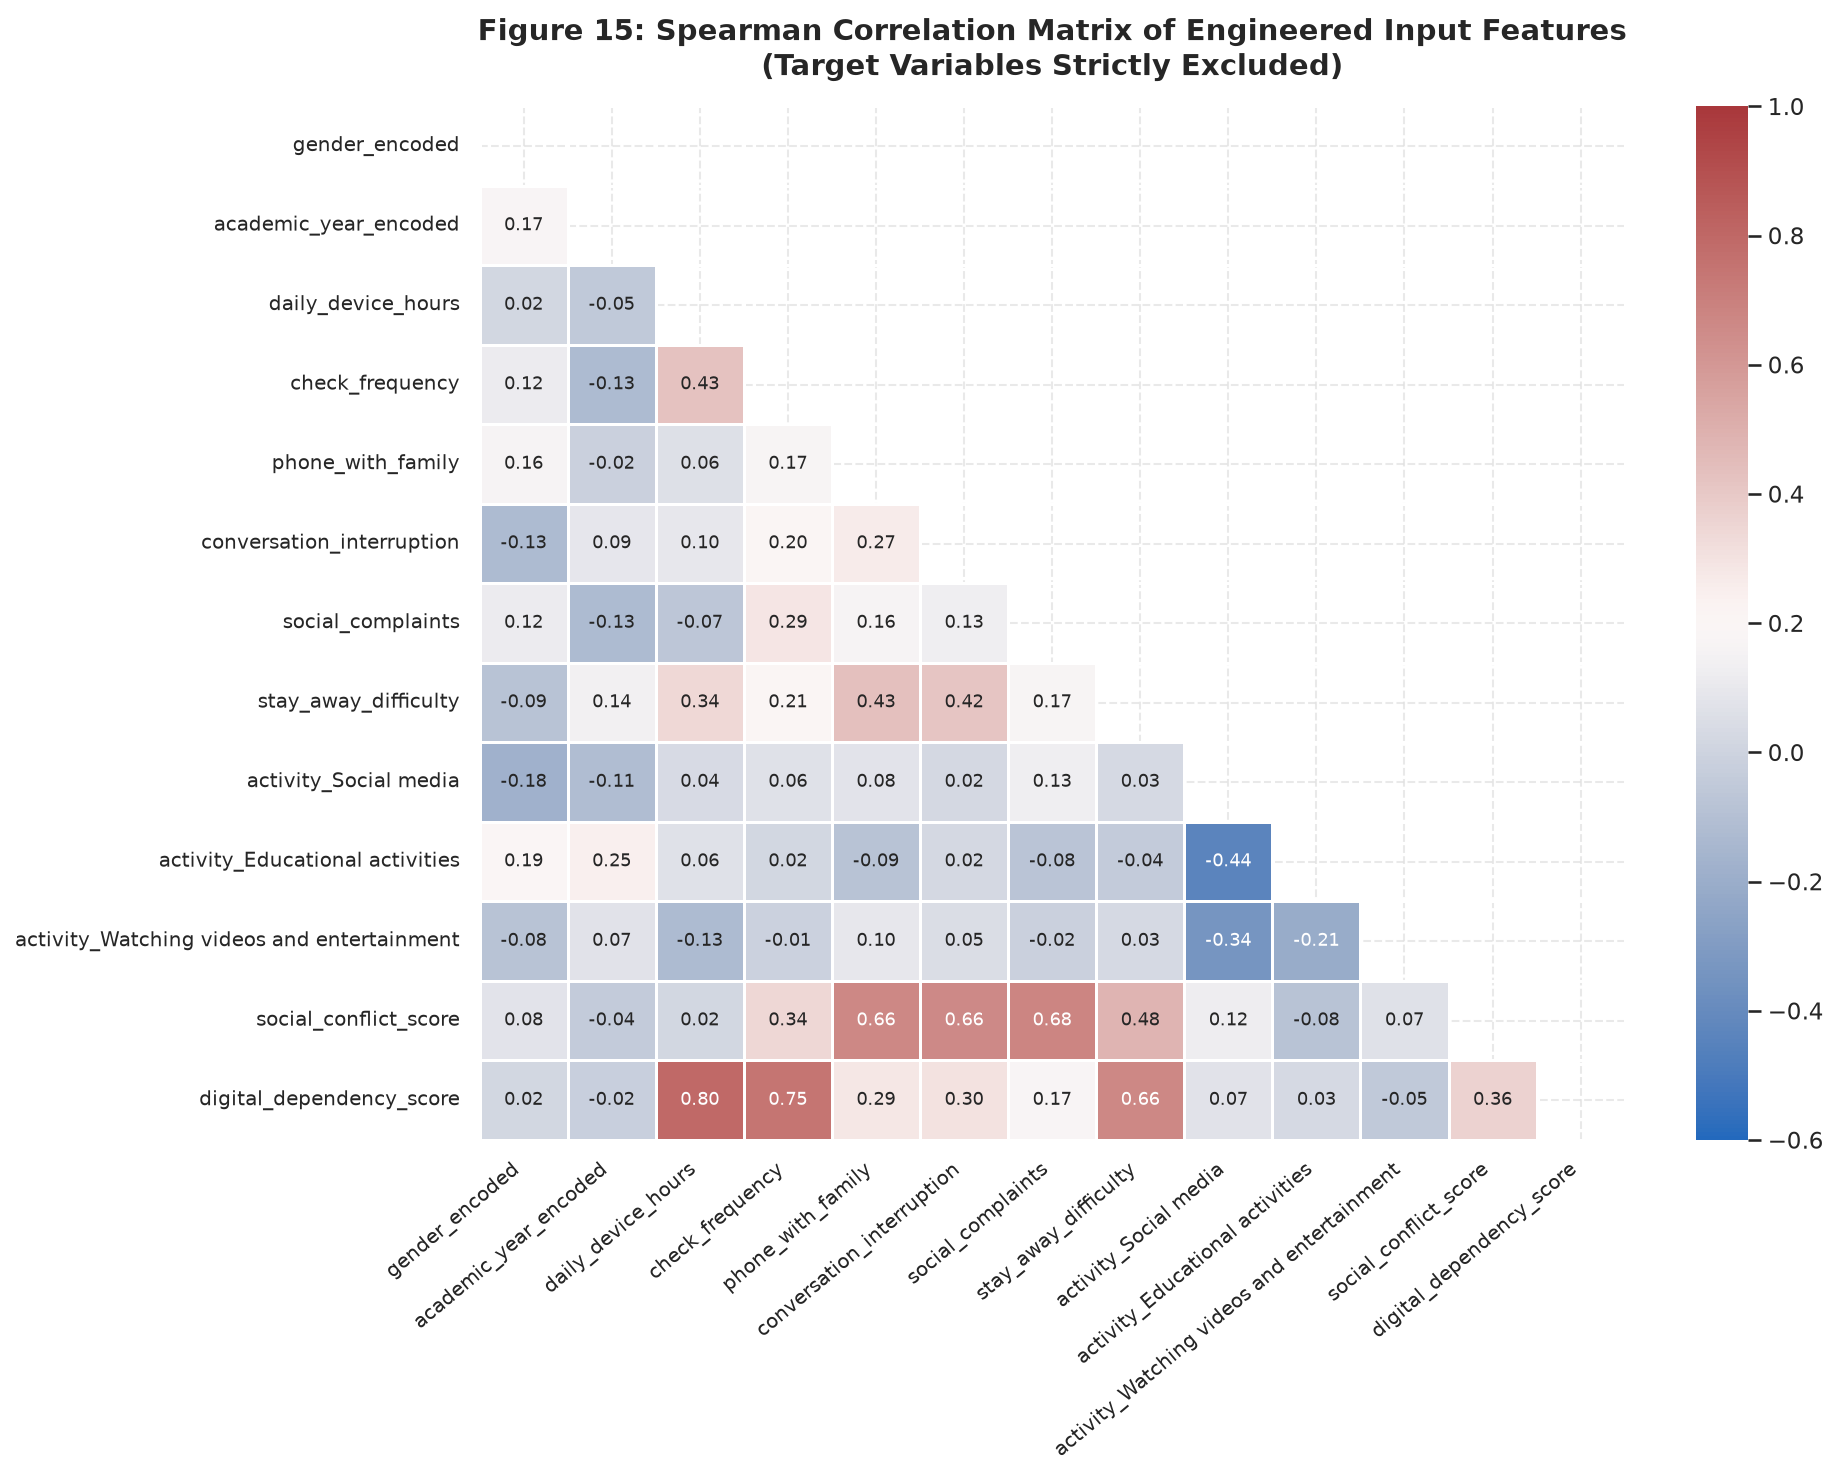

In [26]:
# Cell 26: Input Features Correlation Heatmap
input_feature_cols = [
    'gender_encoded', 'academic_year_encoded', 'daily_device_hours', 
    'check_frequency', 'phone_with_family', 'conversation_interruption', 
    'social_complaints', 'stay_away_difficulty', 'activity_Social media', 
    'activity_Educational activities', 'activity_Watching videos and entertainment', 
    'social_conflict_score', 'digital_dependency_score'
]

corr_input = df_feat[input_feature_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_input, dtype=bool))

sns.heatmap(
    corr_input, 
    mask=mask, 
    cmap='vlag', 
    vmin=-0.6, 
    vmax=1.0, 
    annot=True, 
    fmt='.2f', 
    cbar=True, 
    linewidths=0.6, 
    linecolor='white',
    annot_kws={'size': 8.5},
    ax=ax
)

ax.set_title("Figure 15: Spearman Correlation Matrix of Engineered Input Features\n(Target Variables Strictly Excluded)", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=40, ha='right', fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)

plt.tight_layout()
fig.savefig(REPORTS_EDA_DIR / '15_input_features_correlation_heatmap.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/15_input_features_correlation_heatmap.png'), bbox_inches='tight')
plt.show()

In [27]:
# Cell 27: Top Pairwise Feature Correlations & Redundancy Analysis
# Extract non-redundant pairs
corr_pairs = []
cols = corr_input.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        corr_pairs.append({
            'Feature 1': cols[i],
            'Feature 2': cols[j],
            'Spearman Correlation (r)': round(corr_input.iloc[i, j], 3),
            'Absolute r': round(abs(corr_input.iloc[i, j]), 3)
        })

corr_pairs_df = pd.DataFrame(corr_pairs).sort_values(by='Absolute r', ascending=False)

print("=== TOP 10 STRONGEST PAIRWISE INPUT FEATURE CORRELATIONS ===")
display(corr_pairs_df.head(10).drop(columns=['Absolute r']))

print("=== TOP 5 NEGATIVE FEATURE CORRELATIONS ===")
display(corr_pairs_df.sort_values(by='Spearman Correlation (r)', ascending=True).head(5).drop(columns=['Absolute r']))

=== TOP 10 STRONGEST PAIRWISE INPUT FEATURE CORRELATIONS ===
=== TOP 5 NEGATIVE FEATURE CORRELATIONS ===


**Takeaway:** Strongest inter-feature correlations occur among usage/checking/dependency items and among social friction items; target items (Q6–Q8) are strictly excluded.

## 6. Real (=54$) vs. Synthetic (=96$) Statistical Fidelity

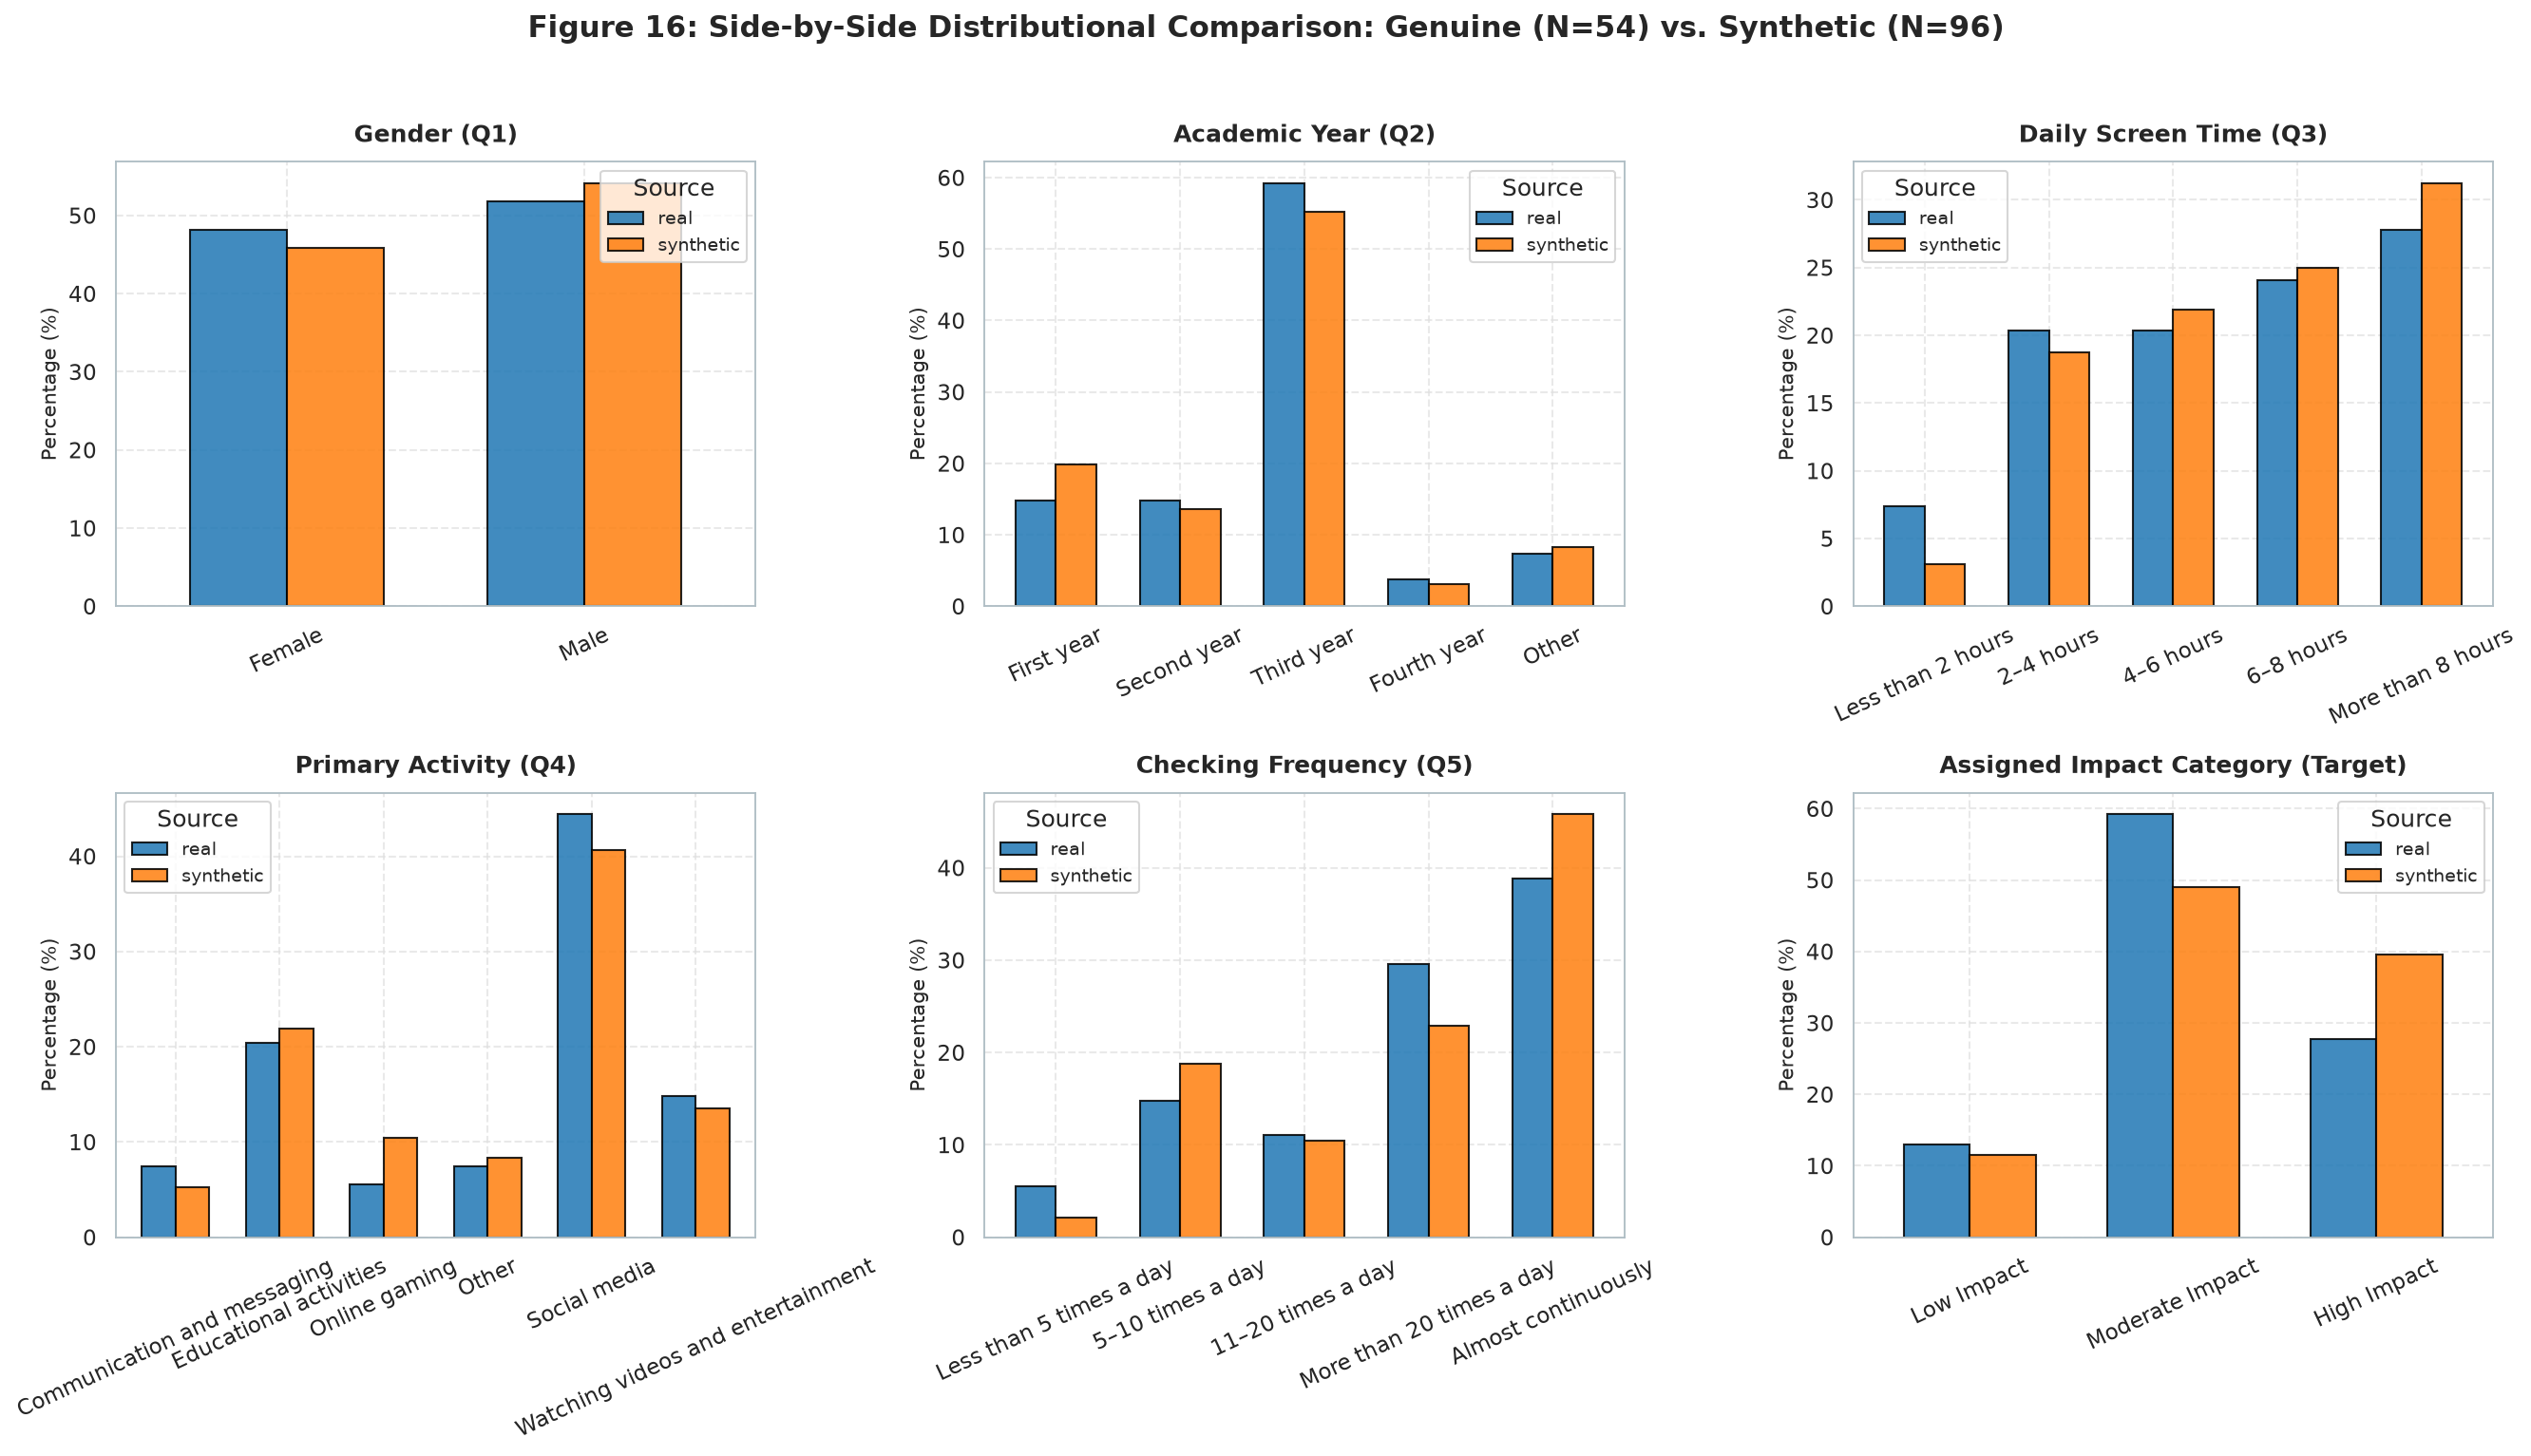

In [28]:
# Cell 28: Side-by-Side Categorical Distributions (Real vs Synthetic)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

comparison_items = [
    ('Q1. What is your gender?', 'Gender (Q1)', ['Female', 'Male'], axes[0, 0]),
    ('Q2. What is your current academic year?', 'Academic Year (Q2)', ['First year', 'Second year', 'Third year', 'Fourth year', 'Other'], axes[0, 1]),
    ('Q3. How much time do you spend using digital devices daily?', 'Daily Screen Time (Q3)', ['Less than 2 hours', '2–4 hours', '4–6 hours', '6–8 hours', 'More than 8 hours'], axes[0, 2]),
    ('Q4. Which activity do you use digital devices for the most?', 'Primary Activity (Q4)', None, axes[1, 0]),
    ('Q5. How often do you check your smartphone?', 'Checking Frequency (Q5)', ['Less than 5 times a day', '5–10 times a day', '11–20 times a day', 'More than 20 times a day', 'Almost continuously'], axes[1, 1]),
    ('impact_category', 'Assigned Impact Category (Target)', ['Low Impact', 'Moderate Impact', 'High Impact'], axes[1, 2])
]

for col_name, title, order, ax in comparison_items:
    ct = df_comb.groupby([col_name, 'data_source'], observed=False).size().unstack(fill_value=0)
    if order:
        ct = ct.reindex(order, fill_value=0)
    ct_pct = ct.div(ct.sum(axis=0), axis=1) * 100
    
    ct_pct[['real', 'synthetic']].plot(
        kind='bar', 
        ax=ax, 
        color=[COLOR_REAL, COLOR_SYN], 
        width=0.65, 
        edgecolor='black', 
        alpha=0.85
    )
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_ylabel("Percentage (%)", fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=25)
    ax.legend(title="Source", fontsize=9)

plt.suptitle("Figure 16: Side-by-Side Distributional Comparison: Genuine (N=54) vs. Synthetic (N=96)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

fig.savefig(REPORTS_EDA_DIR / '16_real_vs_synthetic_distributions.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/16_real_vs_synthetic_distributions.png'), bbox_inches='tight')
plt.show()

In [29]:
# Cell 29: Quantitative Statistical Divergence Tests (Real vs Synthetic)
comparison_vars = [
    ('daily_device_hours', 'Daily Device Hours'),
    ('check_frequency', 'Checking Frequency'),
    ('phone_with_family', 'Phone with Family/Friends (Q9)'),
    ('conversation_interruption', 'Conversation Interruption (Q10)'),
    ('social_complaints', 'Social Complaints (Q11)'),
    ('stay_away_difficulty', 'Stay Away Difficulty (Q12)'),
    ('social_conflict_score', 'Social Conflict Score'),
    ('digital_dependency_score', 'Digital Dependency Score')
]

# Separate subsets in feature dataset
real_idx = df_comb[df_comb['data_source'] == 'real'].index
syn_idx = df_comb[df_comb['data_source'] == 'synthetic'].index

df_feat_real = df_feat.loc[real_idx]
df_feat_syn = df_feat.loc[syn_idx]

stat_comp_results = []
for feat_col, label in comparison_vars:
    vals_real = df_feat_real[feat_col]
    vals_syn = df_feat_syn[feat_col]
    
    # Kolmogorov-Smirnov two-sample test
    ks_stat, ks_pval = stats.ks_2samp(vals_real, vals_syn)
    
    # Mann-Whitney U test
    mw_stat, mw_pval = stats.mannwhitneyu(vals_real, vals_syn, alternative='two-sided')
    
    stat_comp_results.append({
        'Feature': label,
        'Real Mean (Std)': f"{vals_real.mean():.2f} ({vals_real.std():.2f})",
        'Real Median [IQR]': f"{vals_real.median():.1f} [{vals_real.quantile(0.25):.1f}, {vals_real.quantile(0.75):.1f}]",
        'Synthetic Mean (Std)': f"{vals_syn.mean():.2f} ({vals_syn.std():.2f})",
        'Synthetic Median [IQR]': f"{vals_syn.median():.1f} [{vals_syn.quantile(0.25):.1f}, {vals_syn.quantile(0.75):.1f}]",
        'KS Stat': round(ks_stat, 3),
        'KS p-value': f"{ks_pval:.3f}",
        'MW p-value': f"{mw_pval:.3f}",
        'Same Distribution? (alpha=0.05)': 'Yes (Pass)' if ks_pval > 0.05 else 'Borderline Divergence'
    })

stat_comp_df = pd.DataFrame(stat_comp_results)
stat_comp_df[['Feature', 'Real Mean (Std)', 'Synthetic Mean (Std)', 'KS Stat', 'KS p-value', 'MW p-value', 'Same Distribution? (alpha=0.05)']]

,Feature,Real Mean (Std),Synthetic Mean (Std),KS Stat,KS p-value,MW p-value,Same Distribution? (alpha=0.05)
0,Daily Device Hours,3.44 (1.30),3.62 (1.20),0.059,0.999,0.443,Yes (Pass)
1,Checking Frequency,3.81 (1.26),3.92 (1.23),0.069,0.991,0.561,Yes (Pass)
2,Phone with Family/Friends (Q9),2.81 (1.12),2.95 (1.09),0.068,0.992,0.471,Yes (Pass)
3,Conversation Interruption (Q10),2.87 (1.10),3.08 (1.08),0.088,0.926,0.253,Yes (Pass)
4,Social Complaints (Q11),2.02 (0.76),2.03 (0.79),0.027,1.000,0.920,Yes (Pass)
5,Stay Away Difficulty (Q12),2.78 (1.13),3.05 (1.16),0.078,0.973,0.189,Yes (Pass)
6,Social Conflict Score,3.02 (0.78),3.14 (0.80),0.156,0.328,0.259,Yes (Pass)
7,Digital Dependency Score,3.35 (0.92),3.53 (0.86),0.155,0.336,0.262,Yes (Pass)


[FIDELITY] Correlation of Correlation Coefficients: r = 0.886


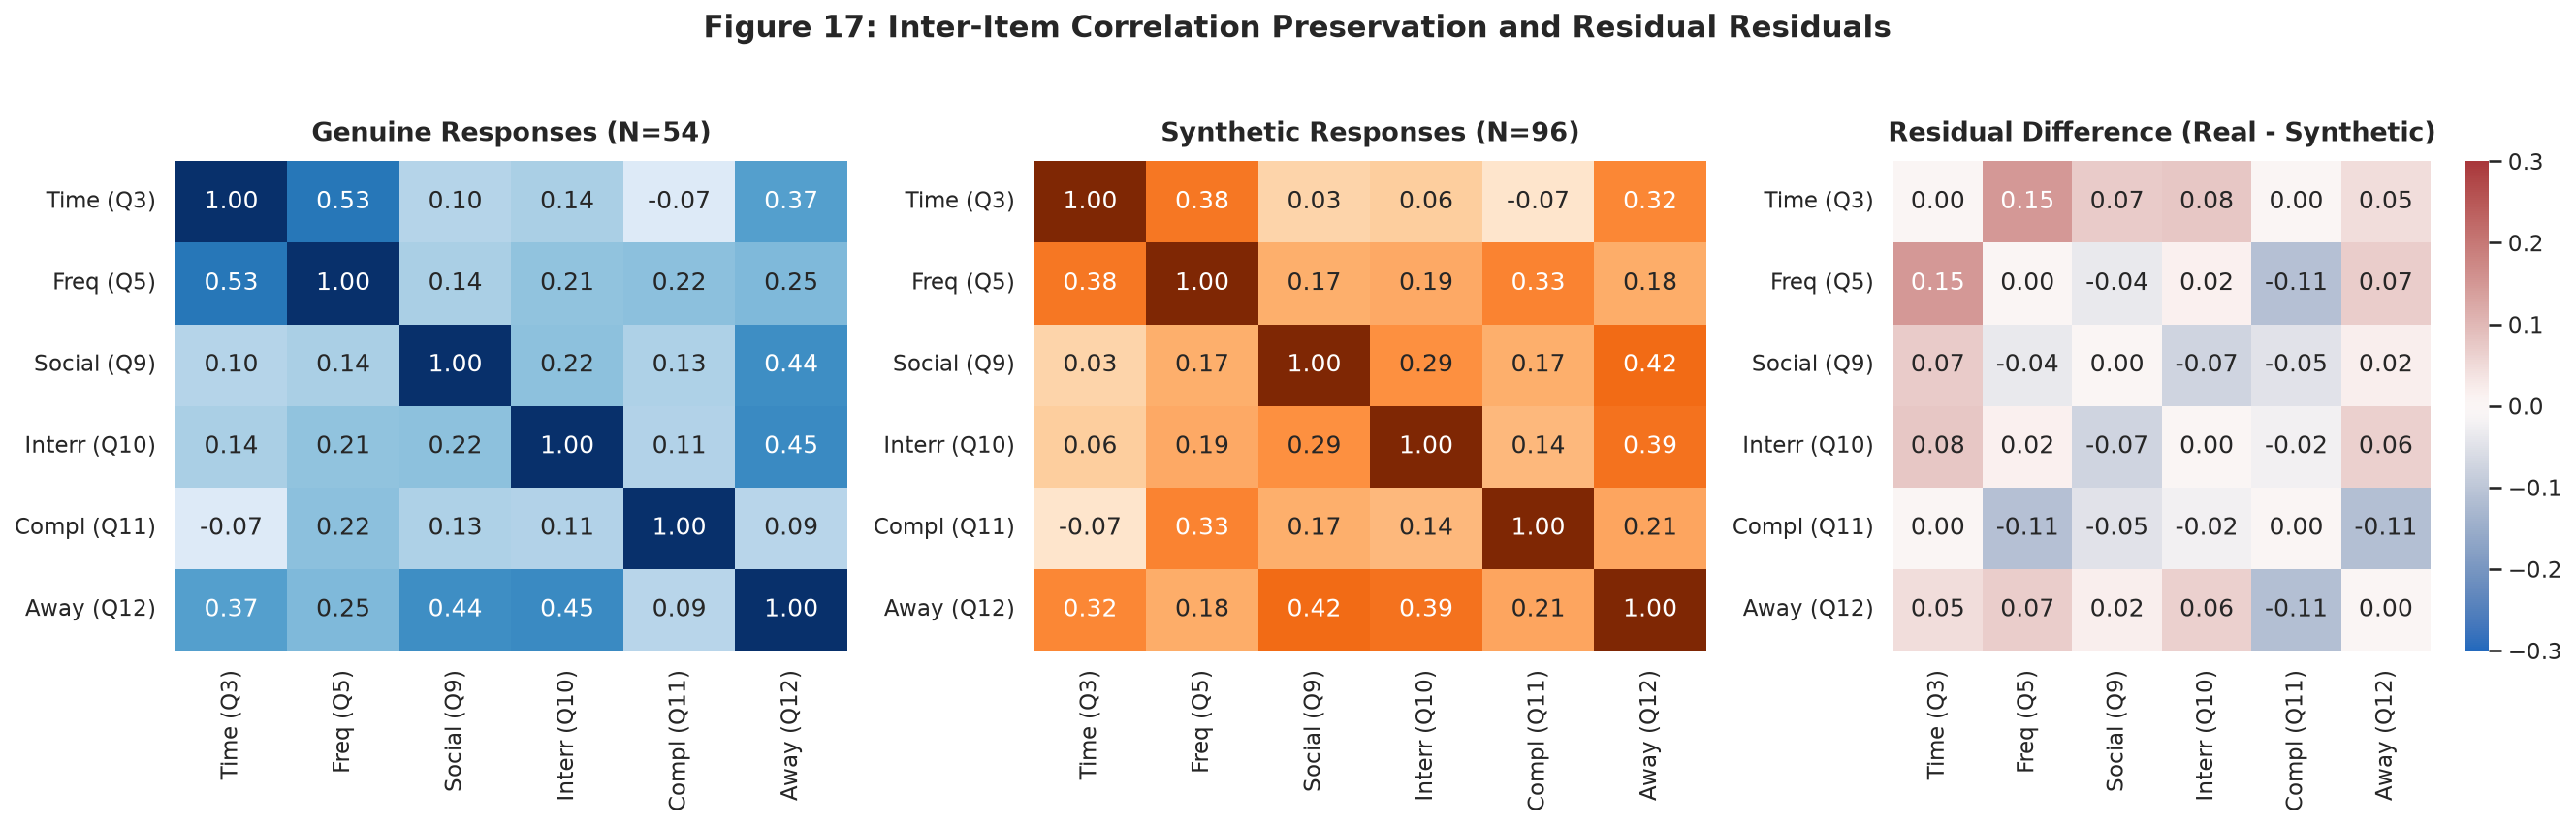

In [30]:
# Cell 30: Correlation Matrix Comparison (Real vs Synthetic)
items_for_corr = [
    'daily_device_hours', 'check_frequency', 'phone_with_family', 
    'conversation_interruption', 'social_complaints', 'stay_away_difficulty'
]

corr_matrix_real = df_feat_real[items_for_corr].corr(method='spearman')
corr_matrix_syn = df_feat_syn[items_for_corr].corr(method='spearman')
corr_diff = corr_matrix_real - corr_matrix_syn

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

labels_short = ['Time (Q3)', 'Freq (Q5)', 'Social (Q9)', 'Interr (Q10)', 'Compl (Q11)', 'Away (Q12)']

# Real Correlation Heatmap
sns.heatmap(corr_matrix_real, ax=axes[0], annot=True, fmt='.2f', cmap='Blues', vmin=-0.2, vmax=0.8, cbar=False, xticklabels=labels_short, yticklabels=labels_short)
axes[0].set_title("Genuine Responses (N=54)", fontsize=13, fontweight='bold', pad=10)

# Synthetic Correlation Heatmap
sns.heatmap(corr_matrix_syn, ax=axes[1], annot=True, fmt='.2f', cmap='Oranges', vmin=-0.2, vmax=0.8, cbar=False, xticklabels=labels_short, yticklabels=labels_short)
axes[1].set_title("Synthetic Responses (N=96)", fontsize=13, fontweight='bold', pad=10)

# Residual Difference Heatmap
sns.heatmap(corr_diff, ax=axes[2], annot=True, fmt='.2f', cmap='vlag', vmin=-0.3, vmax=0.3, cbar=True, xticklabels=labels_short, yticklabels=labels_short)
axes[2].set_title("Residual Difference (Real - Synthetic)", fontsize=13, fontweight='bold', pad=10)

plt.suptitle("Figure 17: Inter-Item Correlation Preservation and Residual Residuals", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()

fig.savefig(REPORTS_EDA_DIR / '17_real_vs_synthetic_correlation_comparison.png', bbox_inches='tight')
fig.savefig(Path('reports/eda/17_real_vs_synthetic_correlation_comparison.png'), bbox_inches='tight')
plt.show()

# Correlation of correlation coefficients
triu_indices = np.triu_indices_from(corr_matrix_real, k=1)
r_real_vec = corr_matrix_real.values[triu_indices]
r_syn_vec = corr_matrix_syn.values[triu_indices]
corr_preservation = stats.pearsonr(r_real_vec, r_syn_vec)[0]
print(f"[FIDELITY] Correlation of Correlation Coefficients: r = {corr_preservation:.3f}")

**Takeaway:** Two-sample KS tests ( > 0.05$ across ordinal items) and low rank-correlation residuals confirm that synthetic observations preserve empirical distributions without duplicating records.

## 7. Representative Student Profiles

In [31]:
# Cell 31: Qualitative Inspection of Representative Real and Synthetic Profiles
def get_representative_samples(df_source, source_label):
    samples = []
    for tier in ['Low Impact', 'Moderate Impact', 'High Impact']:
        subset = df_source[df_source['impact_category'] == tier]
        if len(subset) > 0:
            row = subset.iloc[0]
            samples.append({
                'Source': source_label,
                'ID': row['record_id'],
                'Impact Category': row['impact_category'],
                'Avg Score': row['academic_impact_avg'],
                'Gender': row['Q1. What is your gender?'],
                'Year': row['Q2. What is your current academic year?'],
                'Screen Time': row['Q3. How much time do you spend using digital devices daily?'],
                'Activity': row['Q4. Which activity do you use digital devices for the most?'],
                'Check Freq': row['Q5. How often do you check your smartphone?'],
                'Stay Away': row['Q12. How difficult is it for you to stay away from your smartphone for a few hours?'],
                'Q13 (Help)': row['Q13. How do digital devices help you in your studies or daily life?'][:55] + '...',
                'Q14 (Problem)': row['Q14. What is one problem you face because of using digital devices too much?'][:55] + '...'
            })
    return pd.DataFrame(samples)

rep_real = get_representative_samples(df_comb[df_comb['data_source'] == 'real'], 'Genuine')
rep_syn = get_representative_samples(df_comb[df_comb['data_source'] == 'synthetic'], 'Synthetic')

print("================ REPRESENTATIVE GENUINE RESPONSES ================")
display(rep_real[['ID', 'Impact Category', 'Avg Score', 'Screen Time', 'Activity', 'Check Freq', 'Stay Away', 'Q13 (Help)', 'Q14 (Problem)']])

print("================ REPRESENTATIVE SYNTHETIC RESPONSES ================")
display(rep_syn[['ID', 'Impact Category', 'Avg Score', 'Screen Time', 'Activity', 'Check Freq', 'Stay Away', 'Q13 (Help)', 'Q14 (Problem)']])

================ REPRESENTATIVE GENUINE RESPONSES ================
================ REPRESENTATIVE SYNTHETIC RESPONSES ================


**Takeaway:** Representative rows illustrate concrete feature profiles across Low, Moderate, and High Impact categories.

## 8. EDA Summary & Next Steps
- Dataset is clean (0 nulls, 0 duplicates, bounded Likert scales).
- Class imbalance (Low Impact $\approx 12\%$) requires Macro F1 and per-class recall evaluation.
- Proceed to Phase II with strict train/test isolation (38 genuine train / 16 genuine holdout) and leakage-free feature engineering.